# UPI Transaction Fraud Detection
**Name and Roll Number:** Nidhi Sharma - 24csu140

**Flow:**
1. Load Data -> 2. Basic Commands -> 3. Data Cleaning -> 4. EDA -> 5. Preprocessing -> 6. Feature Selection
-> 7. Choosing Final Features (Version 2 and Version 3) -> 8. Model Building -> 9. Evaluation
-> 10. Risk Score -> 11. New Transactions -> 12. Explainable AI (SHAP) -> 13. K-Means Clustering
-> 14. Export for the Streamlit App

This notebook keeps **both versions** of the project:
- **Version 2 (Model A):** 4 behaviour features
- **Version 3 (Model B):** the best 5 features out of 1,287 combinations

SHAP explains the best model of Version 3. K-Means clustering is a separate analysis and does **not** change the classification scores.

> Run the cells **from top to bottom, one by one** (Shift + Enter).

# 1. Load and Understand the Dataset

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

In [5]:
# Load the dataset
CSV_PATH = r"C:\Users\Ram Bali\OneDrive\Desktop\UPI_Project\fraud_dataset.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset loaded from:", CSV_PATH)
print("Dataset shape:", df.shape)

Dataset loaded from: C:\Users\Ram Bali\OneDrive\Desktop\UPI_Project\fraud_dataset.csv
Dataset shape: (26393, 65)


# 2. Basic Commands

In [6]:
# Look at the first 5 rows
display(df.head(5))

,transaction_id,user_id,merchant_id,amount,timestamp,description,device_id,ip_address,location,session_duration,...,handle_similarity_score,handle_contains_official_terms,handle_typo_analysis,handle_transaction_history,business_name_match,social_media_presence,handle_registration_pattern,handle_to_description_consistency,handle_verification_status,is_fraud
0,7d4e9561-000c-44c8-84e4-54af2c4ac209,michelle89,8bdff36c-efba-4260-a801-8bd36f0f2eb0,1960.754748,18:27.7,Payment to Lee-Warren for products,0c51ef4f-41a8-41da-b721-b74a8055dc4c,49.221.248.16,"(14.5837385, 85.305345)",234,...,0.0,0,none,0,none,none,none,0,verified,0
1,fbf88cde-dc62-4f36-ac10-a1b1fd771793,eguerrero,a28f2b48-5423-4eb6-9018-00e6e55410af,4593.854621,34:55.5,"Payment to Wright, Johnson and Parker for prod...",932aab8b-af95-4214-b555-7f5f2d67308c,106.79.40.40,"(-41.063726, -164.178102)",98,...,0.0,0,none,0,none,none,none,0,verified,0
2,d746c963-baaa-46a0-80f4-b050e14e1c7d,alexanderpatrick,ce4ed336-6b99-42f2-88ca-dba320b8a96f,1949.587163,49:42.8,Payment to Hanson Ltd for products,0dc46fa1-fb1f-4bc6-9e03-af19e1c46e1b,125.165.248.30,"(52.1582705, -162.522989)",100,...,0.0,0,none,0,none,none,none,0,verified,0
3,e5f8a1cc-4bf6-46d2-b9b2-aa393ff4e244,timothy32,3a6129b8-6cdd-4c5a-9bf5-a312da5a9fd3,2825.569899,16:29.9,"Payment to Garcia, Barron and Wood for services",2cc9e843-b5b2-41cf-a6db-aa7fc659986a,89.223.179.179,"(48.549751, -163.02585)",145,...,0.0,0,none,0,none,none,none,0,verified,0
4,34309820-3aec-4fa4-9518-03437830e1e0,billycalhoun,2e34ad70-ec10-4ac1-895e-2773c6246f62,6509.628443,39:44.7,Payment via link: http://lowe.com/search/wp-co...,b503c1d9-fd00-4289-93b9-e297c98f0228,156.93.45.217,"(-61.0860645, 18.331554)",13,...,0.0,0,none,0,none,none,none,0,unverified,1


In [7]:
# Look at the last 5 rows
display(df.tail())

,transaction_id,user_id,merchant_id,amount,timestamp,description,device_id,ip_address,location,session_duration,...,handle_similarity_score,handle_contains_official_terms,handle_typo_analysis,handle_transaction_history,business_name_match,social_media_presence,handle_registration_pattern,handle_to_description_consistency,handle_verification_status,is_fraud
26388,a9fcaaa8-87f6-4f9e-9a28-6e10928970d9,ucarter,a52c438a-da05-494b-a140-efaccdeef2a5,2990.065603,19:52.2,Payment to Ryan-Lee for products,8bd681b9-27c6-43f0-a09f-d26f1f8b6ced,12.152.136.104,"(63.930842, 10.487879)",177,...,0.0,0,none,0,none,none,none,0,verified,0
26389,5034b135-5795-4ae6-ada3-81dd1754e72e,tjohnson,99c932d9-b68b-4975-a39a-b68402990d5d,6602.319359,18:56.8,Payment to Fuller-Owens for services,07a2bc3b-31e7-460a-bc88-91b009e15dbd,158.31.212.173,"(81.9241255, -18.696792)",63,...,0.0,0,none,0,none,none,none,0,verified,0
26390,0a9256ed-66d6-4a68-a571-1ad8752b84e0,joshuaharris,048b1a2d-987d-4dfa-b68d-17f3bc09a215,28923.658050,07:22.6,Payment to Paytm_clone for premium products,a0697f2e-8321-41dc-9582-fc856802323f,39.14.156.82,"(-49.8408755, -63.869035)",259,...,0.0,0,none,0,none,none,recent,0,unverified,1
26391,f683c6fa-da49-439a-95e0-b272bda08724,mcline,06e41f77-d51d-4522-be8e-71a79083fe11,2279.373776,32:37.4,Payment to Smith and Sons for services,8d846731-fece-4837-950d-cac5c2951ebe,8.37.224.40,"(-47.1112205, -146.444328)",124,...,0.0,0,none,0,none,none,none,0,verified,0
26392,63bbf9a4-5a96-4659-9ac7-f14c4c39135b,katherine10,edf2561c-c470-4bb7-b404-cbf159abafae,2211.995646,31:04.2,Payment to Cooper-Lynch for products,53eedade-9168-422d-a4b2-65b24f53e385,2.133.188.51,"(76.6913385, -179.21614)",279,...,0.0,0,none,0,none,none,none,0,verified,0


In [8]:
# Check the number of rows and columns
df.shape

(26393, 65)

In [9]:
# Check all column names
df.columns

Index(['transaction_id', 'user_id', 'merchant_id', 'amount', 'timestamp',
       'description', 'device_id', 'ip_address', 'location',
       'session_duration', 'authentication_attempts', 'receiver_account_age',
       'receiver_transaction_history', 'transaction_amount_vs_sender_history',
       'geographic_disparity', 'transaction_time_of_day',
       'merchant_category_code', 'session_source', 'url_referrer',
       'time_between_link_click_and_transaction', 'unusual_device_flag',
       'unusual_ip_flag', 'unusual_location_flag', 'dns_lookup_age',
       'recent_app_installs', 'input_timing_consistency',
       'app_switching_frequency', 'keyboard_input_speed',
       'input_pause_patterns', 'permissions_granted', 'screen_active_time',
       'geographic_location_vs_ip', 'background_data_usage',
       'recognized_screen_sharing_apps', 'authentication_attempt_count',
       'time_between_otp_generation_and_input', 'pin_entry_method',
       'pin_entry_speed', 'unusual_transaction_

In [10]:
# Display data types of each column
print(df.dtypes)

transaction_id                           str
user_id                                  str
merchant_id                              str
amount                               float64
timestamp                                str
                                      ...   
social_media_presence                    str
handle_registration_pattern              str
handle_to_description_consistency      int64
handle_verification_status               str
is_fraud                               int64
Length: 65, dtype: object


In [11]:
# Statistical summary
display(df.describe())

,amount,session_duration,authentication_attempts,receiver_account_age,receiver_transaction_history,transaction_amount_vs_sender_history,geographic_disparity,transaction_time_of_day,time_between_link_click_and_transaction,unusual_device_flag,...,request_acceptance_rate,time_to_respond_to_request,time_pressure_indicators,requester_account_age,upi_handle_age,handle_similarity_score,handle_contains_official_terms,handle_transaction_history,handle_to_description_consistency,is_fraud
count,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,26393.000000,...,26393.000000,26393.000000,26393.000000,26393.000000,26393.0,26393.000000,26393.0,26393.000000,26393.000000,26393.000000
mean,4865.367115,161.625014,1.108589,150.288486,42.332588,3.037531,10005.354810,11.007426,0.499754,0.056454,...,0.005539,0.479938,0.195052,0.098435,0.0,0.006566,0.0,0.073163,0.028303,0.172205
std,5720.508492,89.453321,0.543179,161.297565,31.559755,7.609687,4712.004930,7.071321,3.183178,0.230801,...,0.034060,3.098854,0.728742,0.696858,0.0,0.059918,0.0,0.515511,0.165840,0.377565
min,139.267664,5.000000,1.000000,0.000000,0.000000,0.222799,14.167439,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
25%,2425.484162,88.000000,1.000000,13.000000,11.000000,0.955017,6307.037068,5.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
50%,3685.574962,156.000000,1.000000,96.000000,40.000000,1.513964,10008.865710,10.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
75%,5239.994313,231.000000,1.000000,240.000000,70.000000,2.623680,13708.758450,17.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
max,49970.158580,600.000000,5.000000,723.000000,100.000000,294.628680,19983.477890,23.000000,30.000000,1.000000,...,0.299788,30.000000,5.000000,7.000000,0.0,0.600000,0.0,5.000000,1.000000,1.000000


In [11]:
# Select specific columns for first 10 transactions
display(df[['user_id', 'amount', 'transaction_type', 'is_fraud']].head(10))

,user_id,amount,transaction_type,is_fraud
0,michelle89,1960.754748,payment,0
1,eguerrero,4593.854621,payment,0
2,alexanderpatrick,1949.587163,payment,0
3,timothy32,2825.569899,payment,0
4,billycalhoun,6509.628443,payment,1
5,zacharynielsen,2370.595249,payment,0
6,hfrye,2321.374692,payment,0
7,rogerjohnson,2438.345336,payment,0
8,linda77,241.684124,payment,0
9,crystal81,4982.700905,payment,0


In [12]:
# Find transactions with amount greater than 1000 (first 10 shown)
display(df[df['amount'] > 1000].head(10))
print("Total transactions above 1000:", (df['amount'] > 1000).sum())

,transaction_id,user_id,merchant_id,amount,timestamp,description,device_id,ip_address,location,session_duration,...,handle_similarity_score,handle_contains_official_terms,handle_typo_analysis,handle_transaction_history,business_name_match,social_media_presence,handle_registration_pattern,handle_to_description_consistency,handle_verification_status,is_fraud
0,7d4e9561-000c-44c8-84e4-54af2c4ac209,michelle89,8bdff36c-efba-4260-a801-8bd36f0f2eb0,1960.754748,18:27.7,Payment to Lee-Warren for products,0c51ef4f-41a8-41da-b721-b74a8055dc4c,49.221.248.16,"(14.5837385, 85.305345)",234,...,0.0,0,none,0,none,none,none,0,verified,0
1,fbf88cde-dc62-4f36-ac10-a1b1fd771793,eguerrero,a28f2b48-5423-4eb6-9018-00e6e55410af,4593.854621,34:55.5,"Payment to Wright, Johnson and Parker for prod...",932aab8b-af95-4214-b555-7f5f2d67308c,106.79.40.40,"(-41.063726, -164.178102)",98,...,0.0,0,none,0,none,none,none,0,verified,0
2,d746c963-baaa-46a0-80f4-b050e14e1c7d,alexanderpatrick,ce4ed336-6b99-42f2-88ca-dba320b8a96f,1949.587163,49:42.8,Payment to Hanson Ltd for products,0dc46fa1-fb1f-4bc6-9e03-af19e1c46e1b,125.165.248.30,"(52.1582705, -162.522989)",100,...,0.0,0,none,0,none,none,none,0,verified,0
3,e5f8a1cc-4bf6-46d2-b9b2-aa393ff4e244,timothy32,3a6129b8-6cdd-4c5a-9bf5-a312da5a9fd3,2825.569899,16:29.9,"Payment to Garcia, Barron and Wood for services",2cc9e843-b5b2-41cf-a6db-aa7fc659986a,89.223.179.179,"(48.549751, -163.02585)",145,...,0.0,0,none,0,none,none,none,0,verified,0
4,34309820-3aec-4fa4-9518-03437830e1e0,billycalhoun,2e34ad70-ec10-4ac1-895e-2773c6246f62,6509.628443,39:44.7,Payment via link: http://lowe.com/search/wp-co...,b503c1d9-fd00-4289-93b9-e297c98f0228,156.93.45.217,"(-61.0860645, 18.331554)",13,...,0.0,0,none,0,none,none,none,0,unverified,1
5,766452f2-3b87-4acb-8892-b93352999ccf,zacharynielsen,d25434a1-dc79-4be8-9a60-728eb052eb6b,2370.595249,02:41.8,Payment to Fox-Moore for bill,fb527091-8552-4a66-9465-b6f38cfc0b3c,180.169.87.64,"(-19.118666, -76.580035)",97,...,0.0,0,none,0,none,none,none,0,verified,0
6,31de092d-42dc-49e1-9240-e3de481c28cb,hfrye,4029a30b-5eae-4a4b-9935-78d6234b11ce,2321.374692,17:02.2,"Payment to Barajas, Rich and Jimenez for bill",1adaac1c-d93c-4973-8e7e-b1739f5abe74,193.39.8.117,"(21.4600315, 87.557356)",188,...,0.0,0,none,0,none,none,none,0,verified,0
7,5a978142-7a92-4e57-942e-f993c966aaee,rogerjohnson,0e9e7be9-4ebc-4081-901d-7678725ed994,2438.345336,07:36.1,Payment to Padilla-Hebert for bill,c9c1255d-e47d-48ac-99db-dc1c2e6cff19,19.136.27.177,"(-1.5485825, -97.457314)",80,...,0.0,0,none,0,none,none,none,0,verified,0
9,ce10415b-7124-4e40-97eb-b8046d53f132,crystal81,d82fafff-f5d7-4ad5-947c-f19447bc0a4b,4982.700905,00:36.2,Payment to Rivera-Watson for services,2eaf45d5-3a35-4019-b9ca-93680dff3ed8,48.145.6.248,"(23.476609, 139.403133)",217,...,0.0,0,none,0,none,none,none,0,verified,0
10,2d000434-35e1-43c0-85d6-5ff035ba2a86,rebecca08,5071a896-91c0-4242-9e67-92cc20af37d1,8313.615976,44:41.8,"Payment to Thomas, Hines and Smith for bill",9fe92914-c926-4ec0-afde-3f49e228c43e,120.39.125.123,"(-21.9412285, 151.189197)",65,...,0.0,0,none,0,none,none,none,0,verified,0


Total transactions above 1000: 25479


In [13]:
# Check basic information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26393 entries, 0 to 26392
Data columns (total 65 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   transaction_id                           26393 non-null  str    
 1   user_id                                  26393 non-null  str    
 2   merchant_id                              26393 non-null  str    
 3   amount                                   26393 non-null  float64
 4   timestamp                                26393 non-null  str    
 5   description                              26393 non-null  str    
 6   device_id                                26393 non-null  str    
 7   ip_address                               26393 non-null  str    
 8   location                                 26393 non-null  str    
 9   session_duration                         26393 non-null  int64  
 10  authentication_attempts                  26393 non-null  

In [14]:
# Check missing values
df.isnull().sum()

transaction_id                       0
user_id                              0
merchant_id                          0
amount                               0
timestamp                            0
                                    ..
social_media_presence                0
handle_registration_pattern          0
handle_to_description_consistency    0
handle_verification_status           0
is_fraud                             0
Length: 65, dtype: int64

In [15]:
# Check duplicate rows (count)
df.duplicated().sum()

np.int64(0)

In [16]:
# Check the fraud distribution - Number
df['is_fraud'].value_counts()

is_fraud
0    21848
1     4545
Name: count, dtype: int64

In [17]:
# Check the fraud distribution - Percentage
df['is_fraud'].value_counts(normalize=True) * 100

is_fraud
0    82.779525
1    17.220475
Name: proportion, dtype: float64

In [18]:
# Find fraudulent transactions (first 10 shown)
display(df[df['is_fraud'] == 1].head(10))

,transaction_id,user_id,merchant_id,amount,timestamp,description,device_id,ip_address,location,session_duration,...,handle_similarity_score,handle_contains_official_terms,handle_typo_analysis,handle_transaction_history,business_name_match,social_media_presence,handle_registration_pattern,handle_to_description_consistency,handle_verification_status,is_fraud
4,34309820-3aec-4fa4-9518-03437830e1e0,billycalhoun,2e34ad70-ec10-4ac1-895e-2773c6246f62,6509.628443,39:44.7,Payment via link: http://lowe.com/search/wp-co...,b503c1d9-fd00-4289-93b9-e297c98f0228,156.93.45.217,"(-61.0860645, 18.331554)",13,...,0.00,0,none,0,none,none,none,0,unverified,1
17,d61f3ef0-0065-4fbc-9fe5-8dcb5df35bc2,johnrodriguez,eb7efa90-5c7e-487a-86ce-f3f90c2e0061,7046.355041,10:00.4,Payment via link: https://www.moore-ward.net/a...,53fc84c1-3637-4800-87c7-a81c4975bfa9,53.194.79.147,"(-61.288882, 115.891423)",9,...,0.00,0,none,0,none,none,none,0,unverified,1
23,af247c18-0f17-4173-9f1a-9fe3d714f8d5,ewilliams,9e58d48b-3905-485a-982a-40b856ea9ff1,5235.832806,17:24.6,OTP authentication payment,720d4dd4-77ee-4dc5-9fdd-232da74d3f5b,110.59.100.205,"(21.6542295, 17.472188)",94,...,0.00,0,none,0,none,none,none,0,unverified,1
28,3da5ae3f-d0a4-4b0e-b527-206e7b9e8ecd,evansbill,3e5a7dad-d5c4-4bdd-9de9-02b907624896,2485.879411,07:07.3,Payment via link: http://acosta.info/main/list...,e1430114-edd6-42a1-a2fc-3addea01be8f,107.95.6.17,"(-69.961271, 47.987427)",13,...,0.00,0,none,0,none,none,none,0,unverified,1
33,5d7e5028-4347-4a63-8897-299c1ec981de,evanscarol,1cb3e29e-739b-44c7-8341-e9e711795fd5,9723.093184,53:00.8,Payment to Lawso_clone,96e282ac-d653-49e3-a1d4-bf2152a19622,73.237.139.79,"(55.1109865, 63.758942)",159,...,0.00,0,typo_squatting,4,Lawson LLC,none,recent,1,unverified,1
34,4c152711-e9ce-461b-9ad3-84c0b17c819d,xbeard,c6795650-6b8e-4625-bca0-2dd95aa58040,9184.986215,24:05.8,Payment via link: http://www.ingram.com/tags/a...,6276d6a2-e840-4e86-b4b7-175b5815e612,1.68.36.208,"(-44.9562105, -11.07507)",20,...,0.00,0,none,0,none,none,none,0,unverified,1
43,5e047373-8108-4301-b174-4c7fdc95e1ca,gomezjames,81d03387-60d3-43c3-ad74-8f586bd2a25a,2008.172610,18:53.0,Payment to Thomas and_clone,3d3dbf25-fd0e-4671-a581-0777261facff,202.35.68.121,"(-42.3570365, 106.398376)",107,...,0.25,0,typo_squatting,1,Thomas and Sons,none,recent,1,unverified,1
45,c18ccb9a-1a2d-4724-8f5f-ac26dd301101,vchen,ade3c211-b4fc-4014-8734-083a24af122b,5819.155897,51:42.4,OTP authentication payment,07e26a30-f787-456f-b748-441bca78a4a9,181.253.5.12,"(47.65914, -141.097469)",119,...,0.00,0,none,0,none,none,none,0,unverified,1
71,855fde11-40ab-41b5-8196-6c916c017dd6,hcollins,94527c02-c77f-45ca-aac8-9be017e53000,3412.415049,21:21.4,Remote payment assistance,3fc07ef9-0f10-42ed-8f0e-2536958afe5a,163.64.1.179,"(-80.6120775, 123.589961)",182,...,0.00,0,none,0,none,none,none,0,unverified,1
87,b8b0394b-513e-4432-b12e-eabd56524184,daviskenneth,8ba1a9c1-8f76-42b7-a556-3971aeb8466b,13194.131530,56:55.7,OTP authentication payment,9086d747-af12-47db-a1e8-ca3ac2dadb15,31.217.30.148,"(-48.077449, -61.790369)",90,...,0.00,0,none,0,none,none,none,0,unverified,1


In [19]:
# Using loc
display(df.loc[0:4, ['user_id', 'amount', 'is_fraud']])

,user_id,amount,is_fraud
0,michelle89,1960.754748,0
1,eguerrero,4593.854621,0
2,alexanderpatrick,1949.587163,0
3,timothy32,2825.569899,0
4,billycalhoun,6509.628443,1


In [20]:
# Using iloc
display(df.iloc[0:5, [1, 3, 64]])

,user_id,amount,is_fraud
0,michelle89,1960.754748,0
1,eguerrero,4593.854621,0
2,alexanderpatrick,1949.587163,0
3,timothy32,2825.569899,0
4,billycalhoun,6509.628443,1


In [21]:
# Convert amount column to NumPy array
amount_array = df['amount'].to_numpy()
print("Amount as NumPy Array:")
print(amount_array)

Amount as NumPy Array:
[ 1960.754748  4593.854621  1949.587163 ... 28923.65805   2279.373776
  2211.995646]


In [22]:
# Calculate mean amount
mean_amount = df['amount'].mean()
print("Mean Transaction Amount:", mean_amount)

Mean Transaction Amount: 4865.367114571348


In [23]:
# Calculate maximum and minimum amount
max_amount = df['amount'].max()
min_amount = df['amount'].min()
print("Maximum Transaction Amount:", max_amount)
print("Minimum Transaction Amount:", min_amount)

Maximum Transaction Amount: 49970.15858
Minimum Transaction Amount: 139.2676643


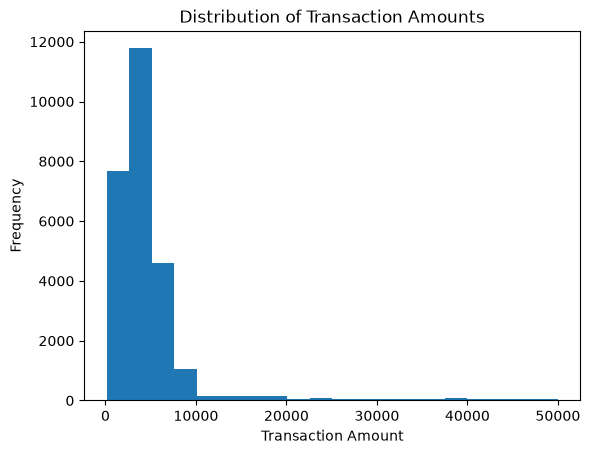

In [24]:
# Plot histogram of amount
plt.hist(df['amount'], bins=20)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Transaction Amounts")
plt.show()

# 3. Data Cleaning

In [25]:
# Missing values with their percentage
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})
display(missing[missing['Missing Values'] > 0])

,Missing Values,Percentage
url_referrer,25636,97.131815
request_description,25661,97.226537


In [26]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [27]:
# Check data types
print(df.dtypes)

transaction_id                           str
user_id                                  str
merchant_id                              str
amount                               float64
timestamp                                str
                                      ...   
social_media_presence                    str
handle_registration_pattern              str
handle_to_description_consistency      int64
handle_verification_status               str
is_fraud                               int64
Length: 65, dtype: object


In [28]:
# Check unique values in the target
print(df['is_fraud'].unique())

[0 1]


In [29]:
# To confirm that: 0 = genuine, 1 = fraudulent
print(df['is_fraud'].value_counts())

is_fraud
0    21848
1     4545
Name: count, dtype: int64


In [30]:
# Check for columns having only one value
constant_columns = df.columns[df.nunique() <= 1]
print("Constant Columns:")
print(constant_columns.tolist())

Constant Columns:
['request_description', 'relationship_to_requester', 'upi_handle_age', 'handle_contains_official_terms', 'social_media_presence']


In [31]:
# Check numerical columns
display(df.select_dtypes(include=np.number).describe().T)

,count,mean,std,min,25%,50%,75%,max
amount,26393.0,4865.367115,5720.508492,139.267664,2425.484162,3685.574962,5239.994313,49970.158580
session_duration,26393.0,161.625014,89.453321,5.000000,88.000000,156.000000,231.000000,600.000000
authentication_attempts,26393.0,1.108589,0.543179,1.000000,1.000000,1.000000,1.000000,5.000000
receiver_account_age,26393.0,150.288486,161.297565,0.000000,13.000000,96.000000,240.000000,723.000000
receiver_transaction_history,26393.0,42.332588,31.559755,0.000000,11.000000,40.000000,70.000000,100.000000
transaction_amount_vs_sender_history,26393.0,3.037531,7.609687,0.222799,0.955017,1.513964,2.623680,294.628680
geographic_disparity,26393.0,10005.354810,4712.004930,14.167439,6307.037068,10008.865710,13708.758450,19983.477890
transaction_time_of_day,26393.0,11.007426,7.071321,0.000000,5.000000,10.000000,17.000000,23.000000
time_between_link_click_and_transaction,26393.0,0.499754,3.183178,0.000000,0.000000,0.000000,0.000000,30.000000
unusual_device_flag,26393.0,0.056454,0.230801,0.000000,0.000000,0.000000,0.000000,1.000000


### Actual Data Cleaning

**Note about `timestamp`:** in this dataset the `timestamp` column is stored like `18:27.7`
(minutes:seconds), not as a full date. Python can read only some of the values, the rest become
`NaT` (missing). So the real hour of the day is taken from the **`transaction_time_of_day`** column
(0 to 23) instead. The timestamp is converted here as in your original code, and removed later in Preprocessing.

In [32]:
# Remove constant columns
constant_columns = df.columns[df.nunique() <= 1]
df = df.drop(columns=constant_columns)

# Remove url_referrer if it still exists (97% of it is empty)
if 'url_referrer' in df.columns:
    df = df.drop(columns=['url_referrer'])

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Check the dataset after cleaning
print("Dataset Shape After Cleaning:", df.shape)
print("______________________________________________________________________________________")
print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("______________________________________________________________________________________")
print("\nRemaining Constant Columns:")
print(df.columns[df.nunique() <= 1].tolist())
print("______________________________________________________________________________________")
print("\nData Types After Cleaning:")
print(df.dtypes)

Dataset Shape After Cleaning: (26393, 59)
______________________________________________________________________________________

Remaining Missing Values:
timestamp    15688
dtype: int64
______________________________________________________________________________________

Remaining Constant Columns:
[]
______________________________________________________________________________________

Data Types After Cleaning:
transaction_id                                        str
user_id                                               str
merchant_id                                           str
amount                                            float64
timestamp                                  datetime64[us]
description                                           str
device_id                                             str
ip_address                                            str
location                                              str
session_duration                                    int6

# 4. Exploratory Data Analysis (EDA)

Fraud Distribution:
is_fraud
0    21848
1     4545
Name: count, dtype: int64

Fraud Distribution (%):
is_fraud
0    82.779525
1    17.220475
Name: proportion, dtype: float64


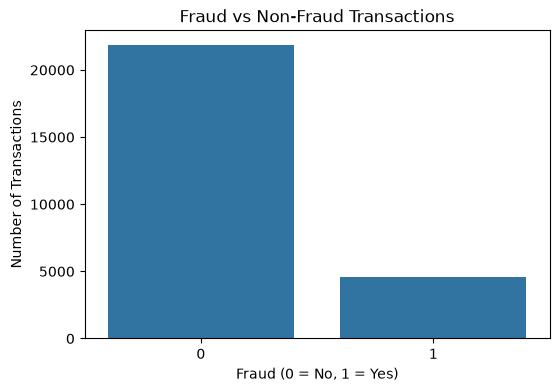

In [33]:
# Fraud vs Non-Fraud Transactions
print("Fraud Distribution:")
print(df['is_fraud'].value_counts())
print("\nFraud Distribution (%):")
print(df['is_fraud'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x='is_fraud', data=df)
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.title("Fraud vs Non-Fraud Transactions")
plt.show()

Transaction Amount Statistics:
count    26393.000000
mean      4865.367115
std       5720.508492
min        139.267664
25%       2425.484162
50%       3685.574962
75%       5239.994313
max      49970.158580
Name: amount, dtype: float64


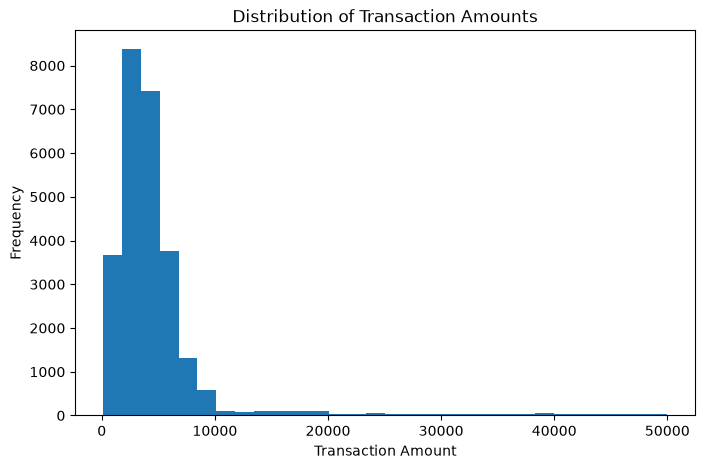

In [34]:
# Transaction Amount Analysis
print("Transaction Amount Statistics:")
print(df['amount'].describe())

plt.figure(figsize=(8, 5))
plt.hist(df['amount'], bins=30)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Transaction Amounts")
plt.show()

Average Transaction Amount:
is_fraud
0     3620.345820
1    10850.235157
Name: amount, dtype: float64
______________________________________________________________________________________

Maximum Transaction Amount:
is_fraud
0    10523.91020
1    49970.15858
Name: amount, dtype: float64
______________________________________________________________________________________

Minimum Transaction Amount:
is_fraud
0    139.267664
1    519.437400
Name: amount, dtype: float64
______________________________________________________________________________________


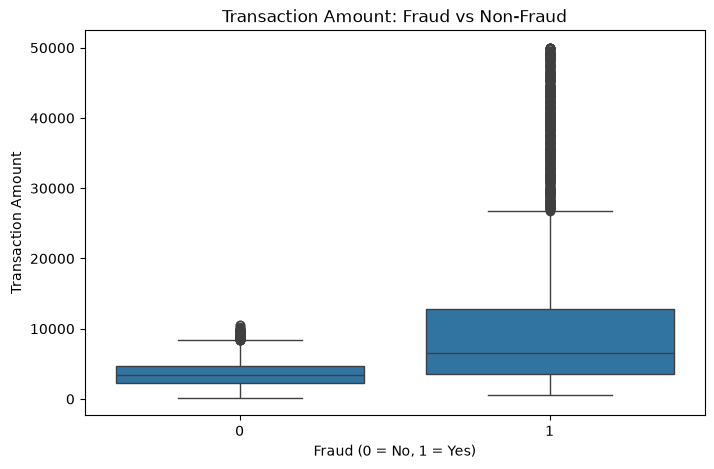

In [35]:
# Transaction Amount: Fraud vs Normal - Are fraudulent transactions associated with higher amounts?
print("Average Transaction Amount:")
print(df.groupby('is_fraud')['amount'].mean())
print("______________________________________________________________________________________")
print("\nMaximum Transaction Amount:")
print(df.groupby('is_fraud')['amount'].max())
print("______________________________________________________________________________________")
print("\nMinimum Transaction Amount:")
print(df.groupby('is_fraud')['amount'].min())
print("______________________________________________________________________________________")

plt.figure(figsize=(8, 5))
sns.boxplot(x='is_fraud', y='amount', data=df)
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.show()

Transaction Type Distribution:
transaction_type
payment               25661
collection_request      732
Name: count, dtype: int64
______________________________________________________________________________________


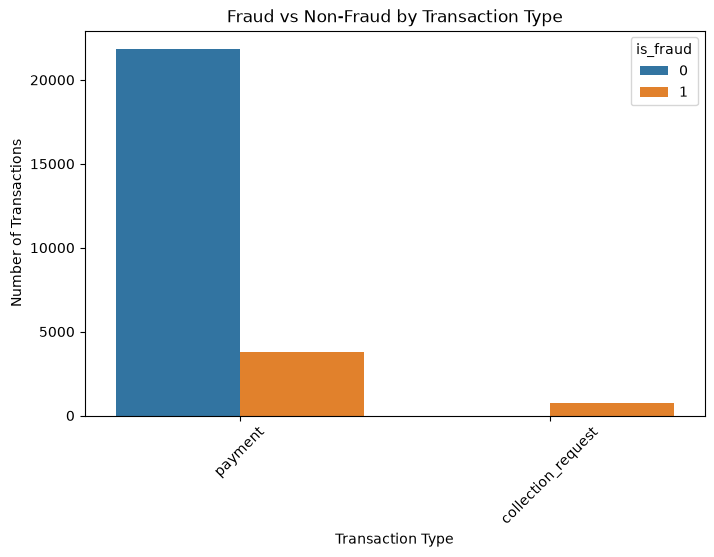

In [36]:
# Fraud by Transaction Type
print("Transaction Type Distribution:")
print(df['transaction_type'].value_counts())
print("______________________________________________________________________________________")

plt.figure(figsize=(8, 5))
sns.countplot(x='transaction_type', hue='is_fraud', data=df)
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.title("Fraud vs Non-Fraud by Transaction Type")
plt.xticks(rotation=45)
plt.show()

Correlation with Fraud:
is_fraud                                   1.000000
unusual_transaction_amount_flag            0.793989
time_pressure_indicators                   0.586844
unusual_device_flag                        0.536298
unusual_ip_flag                            0.528433
unusual_location_flag                      0.528433
authentication_attempt_count               0.518601
amount                                     0.477188
authentication_attempts                    0.438320
input_pause_patterns                       0.398484
handle_to_description_consistency          0.374188
background_data_usage                      0.373664
request_frequency                          0.361464
request_acceptance_rate                    0.356538
otp_request_frequency                      0.356463
transaction_velocity                       0.352950
time_between_otp_generation_and_input      0.346781
time_between_link_click_and_transaction    0.344225
failed_transaction_count                

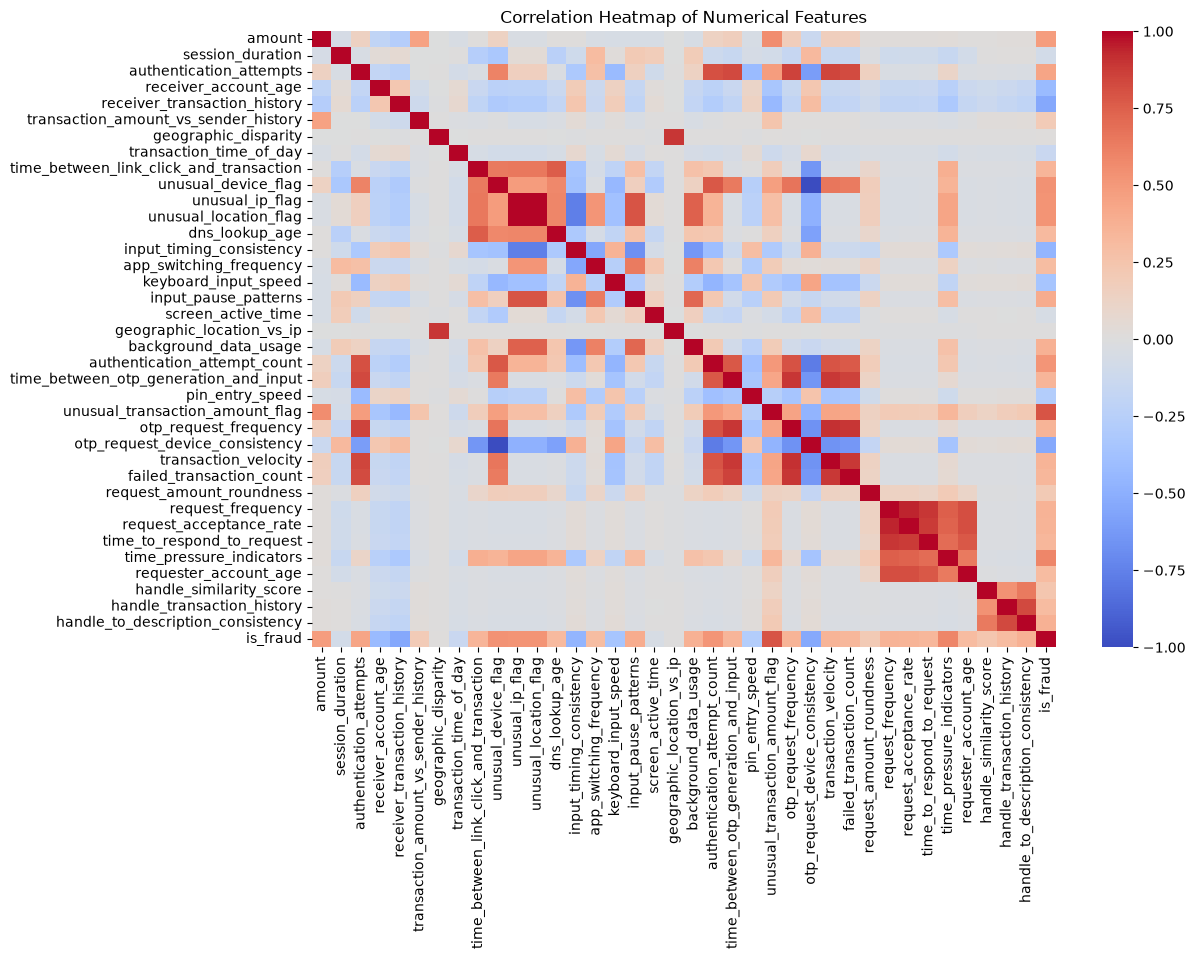

In [37]:
# Correlation Analysis
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

print("Correlation with Fraud:")
print(correlation['is_fraud'].sort_values(ascending=False))
print("______________________________________________________________________________________")

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Fraud Rate by Transaction Type:
transaction_type
collection_request    100.000000
payment                14.859125
Name: is_fraud, dtype: float64
______________________________________________________________________________________


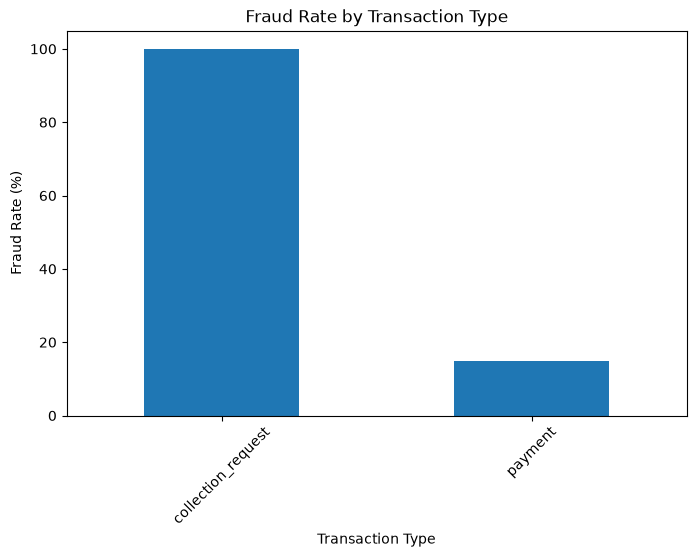

In [38]:
# Fraud Rate by Transaction Type: Which transaction type has the highest fraud rate?
fraud_rate = df.groupby('transaction_type')['is_fraud'].mean() * 100
print("Fraud Rate by Transaction Type:")
print(fraud_rate.sort_values(ascending=False))
print("______________________________________________________________________________________")

plt.figure(figsize=(8, 5))
fraud_rate.sort_values(ascending=False).plot(kind='bar')
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Transaction Type")
plt.xticks(rotation=45)
plt.show()

Fraud Rate by Time of Day:
transaction_time_of_day
6     40.133983
5     35.268817
4     28.639618
3     28.066215
7     27.018385
2     25.205931
1     23.563697
0     20.773381
22    18.428184
23    17.857143
21    15.448659
20    14.935065
19    14.457831
18    10.607522
15     9.417476
16     8.759843
17     8.416834
14     6.342016
12     5.525460
13     5.385428
11     3.846154
10     3.594771
9      1.435897
8      0.542888
Name: is_fraud, dtype: float64
______________________________________________________________________________________


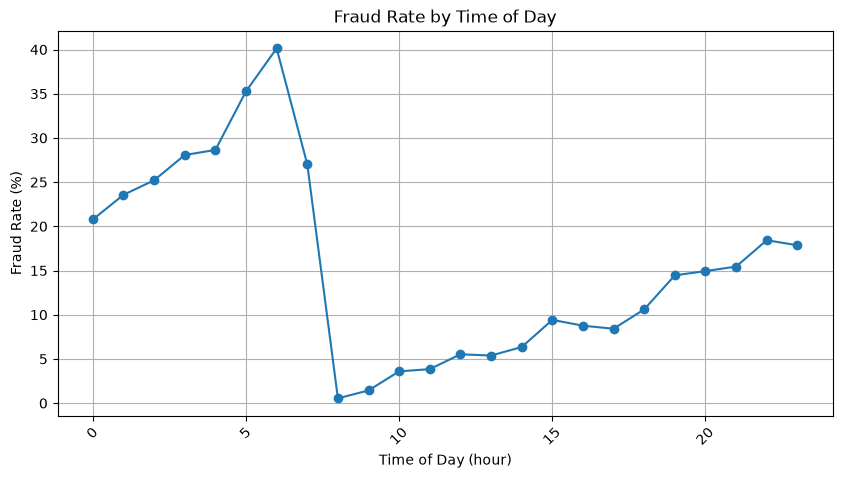

In [39]:
# Fraud by Time of Day: At what time of day does fraud occur most frequently?
fraud_by_time = df.groupby('transaction_time_of_day')['is_fraud'].mean() * 100
print("Fraud Rate by Time of Day:")
print(fraud_by_time.sort_values(ascending=False))
print("______________________________________________________________________________________")

plt.figure(figsize=(10, 5))
fraud_by_time.sort_index().plot(kind='line', marker='o')
plt.xlabel("Time of Day (hour)")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Time of Day")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

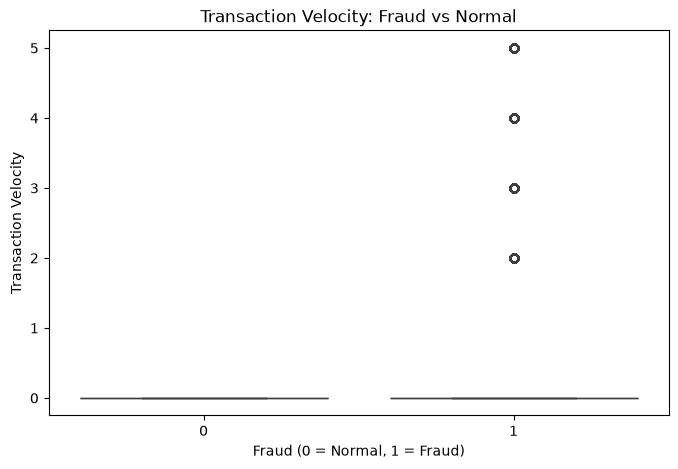

In [40]:
# Transaction Velocity: Fraud vs Normal
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_fraud', y='transaction_velocity', data=df)
plt.xlabel("Fraud (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Velocity")
plt.title("Transaction Velocity: Fraud vs Normal")
plt.show()

Fraud Rate for Unusual Device, IP and Location:


,Feature,Flag,Fraud Rate
0,unusual_device_flag,0,12.267598
1,unusual_device_flag,1,100.000000
2,unusual_ip_flag,0,12.411802
3,unusual_ip_flag,1,100.000000
4,unusual_location_flag,0,12.411802
5,unusual_location_flag,1,100.000000


______________________________________________________________________________________


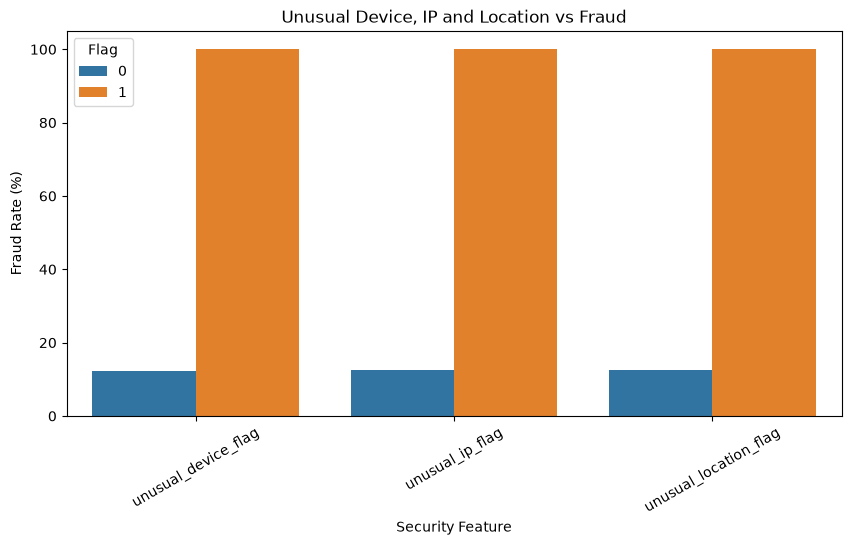

In [41]:
# Unusual Device, IP and Location vs Fraud
security_features = ['unusual_device_flag', 'unusual_ip_flag', 'unusual_location_flag']

fraud_rates = []
for feature in security_features:
    rate = df.groupby(feature)['is_fraud'].mean() * 100
    for value in rate.index:
        fraud_rates.append({'Feature': feature, 'Flag': value, 'Fraud Rate': rate[value]})

security_df = pd.DataFrame(fraud_rates)
print("Fraud Rate for Unusual Device, IP and Location:")
display(security_df)
print("______________________________________________________________________________________")

plt.figure(figsize=(10, 5))
sns.barplot(x='Feature', y='Fraud Rate', hue='Flag', data=security_df)
plt.xlabel("Security Feature")
plt.ylabel("Fraud Rate (%)")
plt.title("Unusual Device, IP and Location vs Fraud")
plt.xticks(rotation=30)
plt.show()

Top 10 Merchant Categories by Fraud Rate:
merchant_category_code
unknown          100.000000
services          12.394829
retail            11.633563
utilities          3.616637
entertainment      3.180522
food               3.156323
Name: is_fraud, dtype: float64
______________________________________________________________________________________


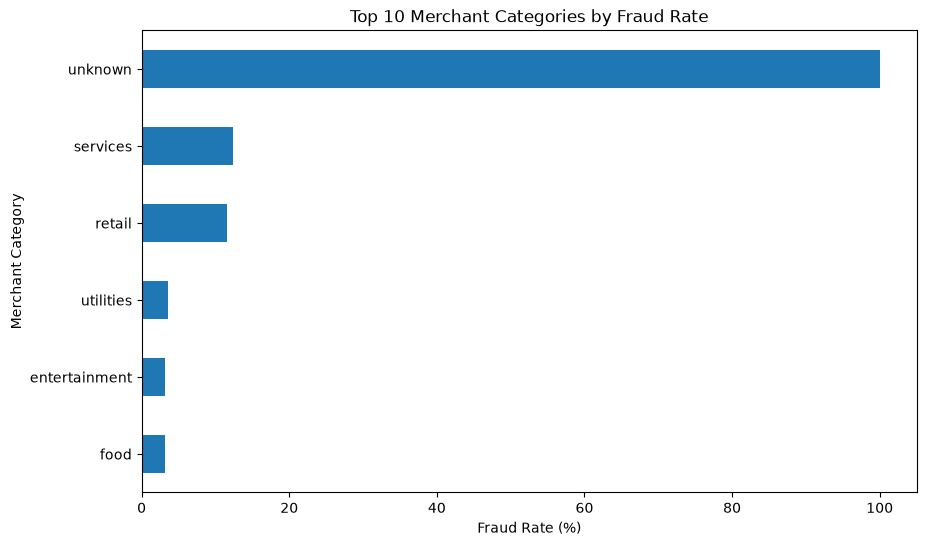

In [42]:
# Fraud Rate by Merchant Category
merchant_fraud = (df.groupby('merchant_category_code')['is_fraud'].mean().sort_values(ascending=False).head(10) * 100)
print("Top 10 Merchant Categories by Fraud Rate:")
print(merchant_fraud)
print("______________________________________________________________________________________")

plt.figure(figsize=(10, 6))
merchant_fraud.sort_values().plot(kind='barh')
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.title("Top 10 Merchant Categories by Fraud Rate")
plt.show()

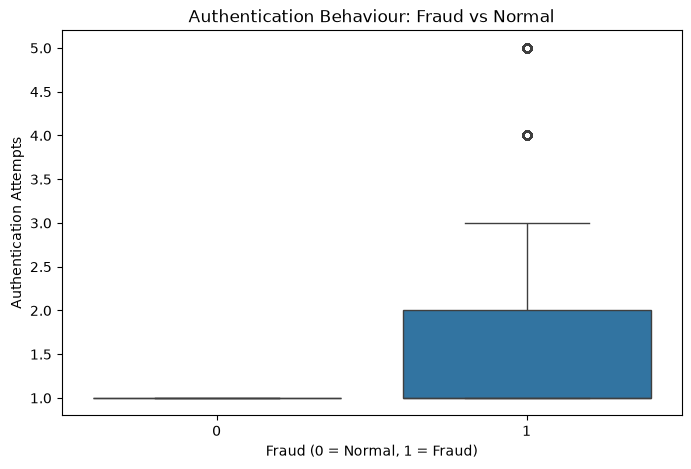

In [43]:
# Authentication Attempts: Fraud vs Normal
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_fraud', y='authentication_attempts', data=df)
plt.xlabel("Fraud (0 = Normal, 1 = Fraud)")
plt.ylabel("Authentication Attempts")
plt.title("Authentication Behaviour: Fraud vs Normal")
plt.show()

Correlation with Fraud:
receiver_transaction_history              -0.541315
otp_request_device_consistency            -0.536298
input_timing_consistency                  -0.465539
receiver_account_age                      -0.424979
keyboard_input_speed                      -0.349177
pin_entry_speed                           -0.275263
transaction_time_of_day                   -0.141843
session_duration                          -0.084663
screen_active_time                        -0.051672
geographic_location_vs_ip                  0.001489
geographic_disparity                       0.010029
transaction_amount_vs_sender_history       0.195881
request_amount_roundness                   0.209000
handle_similarity_score                    0.240272
app_switching_frequency                    0.296941
requester_account_age                      0.309708
handle_transaction_history                 0.311173
dns_lookup_age                             0.313196
time_to_respond_to_request              

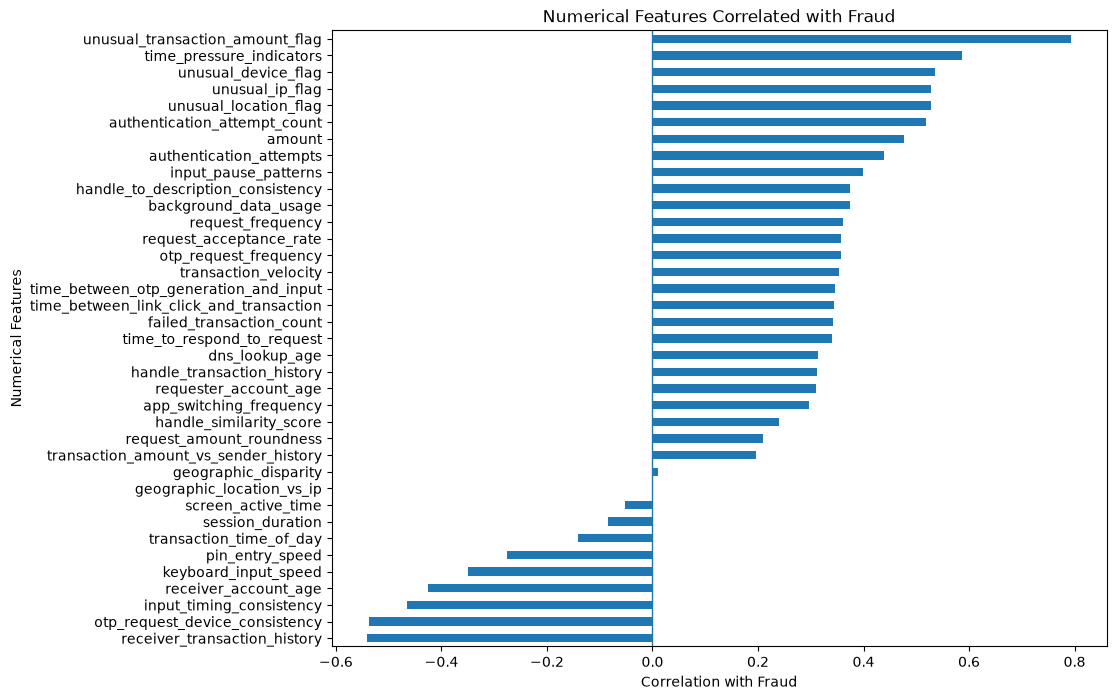

In [44]:
# Numerical Features Most Strongly Related to Fraud
correlation_with_fraud = (numeric_df.corr()['is_fraud'].drop('is_fraud').sort_values())
print("Correlation with Fraud:")
print(correlation_with_fraud)
print("______________________________________________________________________________________")

plt.figure(figsize=(10, 8))
correlation_with_fraud.plot(kind='barh')
plt.xlabel("Correlation with Fraud")
plt.ylabel("Numerical Features")
plt.title("Numerical Features Correlated with Fraud")
plt.axvline(0, linewidth=1)
plt.show()

# 5. Data Preprocessing

In [45]:
# Separate features and target variable
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("_________________________________________________")
print("\nTarget Variable:")
print(y.head())
print("_________________________________________________")
print("\nTimestamp exists:", 'timestamp' in X.columns)

Features Shape: (26393, 58)
Target Shape: (26393,)
_________________________________________________

Target Variable:
0    0
1    0
2    0
3    0
4    1
Name: is_fraud, dtype: int64
_________________________________________________

Timestamp exists: True


## 5.1 Encoding and Scaling Techniques (demonstration)
These cells show the different encoding and scaling techniques on selected columns.
They work on **copies**, so they do not change `X`. The real model data is prepared in **5.2**.

In [46]:
# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(exclude=['number', 'datetime']).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)
print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['amount', 'session_duration', 'authentication_attempts', 'receiver_account_age', 'receiver_transaction_history', 'transaction_amount_vs_sender_history', 'geographic_disparity', 'transaction_time_of_day', 'time_between_link_click_and_transaction', 'unusual_device_flag', 'unusual_ip_flag', 'unusual_location_flag', 'dns_lookup_age', 'input_timing_consistency', 'app_switching_frequency', 'keyboard_input_speed', 'input_pause_patterns', 'screen_active_time', 'geographic_location_vs_ip', 'background_data_usage', 'authentication_attempt_count', 'time_between_otp_generation_and_input', 'pin_entry_speed', 'unusual_transaction_amount_flag', 'otp_request_frequency', 'otp_request_device_consistency', 'transaction_velocity', 'failed_transaction_count', 'request_amount_roundness', 'request_frequency', 'request_acceptance_rate', 'time_to_respond_to_request', 'time_pressure_indicators', 'requester_account_age', 'handle_similarity_score', 'handle_transaction_history', 'handle_to_desc

In [47]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding
label_encoder = LabelEncoder()
X_label = X.copy()

# Converts categories into numerical labels
X_label['transaction_type_label'] = label_encoder.fit_transform(X_label['transaction_type'].astype(str))

print("Label Encoding:")
display(X_label[['transaction_type', 'transaction_type_label']].head(10))

Label Encoding:


,transaction_type,transaction_type_label
0,payment,1
1,payment,1
2,payment,1
3,payment,1
4,payment,1
5,payment,1
6,payment,1
7,payment,1
8,payment,1
9,payment,1


In [48]:
print("Label Encoding Mapping:")
for category, label in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)):
    print(category, "->", label)

Label Encoding Mapping:
collection_request -> 0
payment -> 1


In [49]:
# Create an ordinal categorical feature from session duration
X_ordinal = X.copy()

X_ordinal['session_level'] = pd.cut(X_ordinal['session_duration'],
                                    bins=[-np.inf, 100, 300, np.inf],
                                    labels=['Low', 'Medium', 'High'])

print("Ordinal Categories:")
display(X_ordinal[['session_duration', 'session_level']].head(10))

Ordinal Categories:


,session_duration,session_level
0,234,Medium
1,98,Low
2,100,Low
3,145,Medium
4,13,Low
5,97,Low
6,188,Medium
7,80,Low
8,70,Low
9,217,Medium


In [50]:
from sklearn.preprocessing import OrdinalEncoder

# Ordinal Encoding
ordinal_encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])
X_ordinal['session_level_encoded'] = ordinal_encoder.fit_transform(X_ordinal[['session_level']])

print("Ordinal Encoding:")
display(X_ordinal[['session_level', 'session_level_encoded']].head(10))

Ordinal Encoding:


,session_level,session_level_encoded
0,Medium,1.0
1,Low,0.0
2,Low,0.0
3,Medium,1.0
4,Low,0.0
5,Low,0.0
6,Medium,1.0
7,Low,0.0
8,Low,0.0
9,Medium,1.0


In [51]:
from sklearn.preprocessing import OneHotEncoder

# One-Hot Encoding - converts categories into separate binary columns
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
transaction_type_encoded = onehot_encoder.fit_transform(X[['transaction_type']])
onehot_columns = onehot_encoder.get_feature_names_out(['transaction_type'])
onehot_df = pd.DataFrame(transaction_type_encoded, columns=onehot_columns, index=X.index)

print("One-Hot Encoding:")
display(onehot_df.head(10))

One-Hot Encoding:


,transaction_type_collection_request,transaction_type_payment
0,0.0,1.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,0.0,1.0
5,0.0,1.0
6,0.0,1.0
7,0.0,1.0
8,0.0,1.0
9,0.0,1.0


In [52]:
# Frequency Encoding
X_frequency = X.copy()
frequency_mapping = X_frequency['merchant_category_code'].value_counts(normalize=True)
X_frequency['merchant_category_frequency'] = X_frequency['merchant_category_code'].map(frequency_mapping)

print("Frequency Encoding:")
display(X_frequency[['merchant_category_code', 'merchant_category_frequency']].head(10))

Frequency Encoding:


,merchant_category_code,merchant_category_frequency
0,food,0.177661
1,food,0.177661
2,services,0.184632
3,utilities,0.167620
4,unknown,0.110408
5,services,0.184632
6,services,0.184632
7,entertainment,0.172735
8,food,0.177661
9,utilities,0.167620


In [53]:
# Count Encoding
X_count = X.copy()
count_mapping = X_count['merchant_category_code'].value_counts()
X_count['merchant_category_count'] = X_count['merchant_category_code'].map(count_mapping)

print("Count Encoding:")
display(X_count[['merchant_category_code', 'merchant_category_count']].head(10))

Count Encoding:


,merchant_category_code,merchant_category_count
0,food,4689
1,food,4689
2,services,4873
3,utilities,4424
4,unknown,2914
5,services,4873
6,services,4873
7,entertainment,4559
8,food,4689
9,utilities,4424


In [54]:
from sklearn.feature_extraction import FeatureHasher

# Hash Encoding - converts categories into a fixed number of numerical hash features
hash_encoder = FeatureHasher(n_features=8, input_type='string')
hash_input = X['merchant_category_code'].astype(str).apply(lambda x: [x])
hash_encoded = hash_encoder.transform(hash_input)
hash_encoded_df = pd.DataFrame(hash_encoded.toarray(),
                               columns=[f'hash_feature_{i}' for i in range(8)],
                               index=X.index)

print("Hash Encoding:")
display(hash_encoded_df.head(10))

Hash Encoding:


,hash_feature_0,hash_feature_1,hash_feature_2,hash_feature_3,hash_feature_4,hash_feature_5,hash_feature_6,hash_feature_7
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [55]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for scaling
selected_features_demo = ['amount', 'session_duration', 'authentication_attempts', 'transaction_velocity']
feature_df = X[selected_features_demo].copy()

print("Original Feature Data:")
display(feature_df.head(10))

Original Feature Data:


,amount,session_duration,authentication_attempts,transaction_velocity
0,1960.754748,234,1,0
1,4593.854621,98,1,0
2,1949.587163,100,1,0
3,2825.569899,145,1,0
4,6509.628443,13,1,0
5,2370.595249,97,1,0
6,2321.374692,188,1,0
7,2438.345336,80,1,0
8,241.684124,70,1,0
9,4982.700905,217,1,0


In [56]:
# Standard Scaling
standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(feature_df)
standard_scaled_df = pd.DataFrame(standard_scaled, columns=selected_features_demo, index=X.index)

print("Standard Scaled Data:")
display(standard_scaled_df.head(10))

Standard Scaled Data:


,amount,session_duration,authentication_attempts,transaction_velocity
0,-0.507764,0.809096,-0.199918,-0.160981
1,-0.047464,-0.711278,-0.199918,-0.160981
2,-0.509716,-0.688920,-0.199918,-0.160981
3,-0.356583,-0.185855,-0.199918,-0.160981
4,0.287438,-1.661513,-0.199918,-0.160981
5,-0.436118,-0.722458,-0.199918,-0.160981
6,-0.444723,0.294852,-0.199918,-0.160981
7,-0.424275,-0.912505,-0.199918,-0.160981
8,-0.808280,-1.024297,-0.199918,-0.160981
9,0.020511,0.619050,-0.199918,-0.160981


In [57]:
# Mean and standard deviation after Standard Scaling
print("Mean after Standard Scaling:")
print(standard_scaled_df.mean())
print("\nStandard Deviation after Standard Scaling:")
print(standard_scaled_df.std(ddof=0))

Mean after Standard Scaling:
amount                     1.041867e-16
session_duration          -1.023022e-16
authentication_attempts   -1.243780e-16
transaction_velocity       5.492014e-17
dtype: float64

Standard Deviation after Standard Scaling:
amount                     1.0
session_duration           1.0
authentication_attempts    1.0
transaction_velocity       1.0
dtype: float64


In [58]:
from sklearn.preprocessing import MinMaxScaler

# Min-Max Scaling
minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(feature_df)
minmax_scaled_df = pd.DataFrame(minmax_scaled, columns=selected_features_demo, index=X.index)

print("Min-Max Scaled Data:")
display(minmax_scaled_df.head(10))

Min-Max Scaled Data:


,amount,session_duration,authentication_attempts,transaction_velocity
0,0.036553,0.384874,0.0,0.0
1,0.089394,0.156303,0.0,0.0
2,0.036329,0.159664,0.0,0.0
3,0.053908,0.235294,0.0,0.0
4,0.127840,0.013445,0.0,0.0
5,0.044778,0.154622,0.0,0.0
6,0.043790,0.307563,0.0,0.0
7,0.046138,0.126050,0.0,0.0
8,0.002055,0.109244,0.0,0.0
9,0.097197,0.356303,0.0,0.0


In [59]:
print("Minimum values:")
print(minmax_scaled_df.min())
print("\nMaximum values:")
print(minmax_scaled_df.max())

Minimum values:
amount                     0.0
session_duration           0.0
authentication_attempts    0.0
transaction_velocity       0.0
dtype: float64

Maximum values:
amount                     1.0
session_duration           1.0
authentication_attempts    1.0
transaction_velocity       1.0
dtype: float64


In [60]:
# Combine preprocessing results for demonstration
final_preprocessed_df = pd.concat(
    [
        standard_scaled_df,
        onehot_df,
        X_frequency[['merchant_category_frequency']],
        X_count[['merchant_category_count']],
        hash_encoded_df
    ], axis=1)

print("Final Preprocessed Dataset (demo):")
display(final_preprocessed_df.head())
print("\nFinal Shape:", final_preprocessed_df.shape)
print("\nMissing Values:", final_preprocessed_df.isnull().sum().sum())

Final Preprocessed Dataset (demo):


,amount,session_duration,authentication_attempts,transaction_velocity,transaction_type_collection_request,transaction_type_payment,merchant_category_frequency,merchant_category_count,hash_feature_0,hash_feature_1,hash_feature_2,hash_feature_3,hash_feature_4,hash_feature_5,hash_feature_6,hash_feature_7
0,-0.507764,0.809096,-0.199918,-0.160981,0.0,1.0,0.177661,4689,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.047464,-0.711278,-0.199918,-0.160981,0.0,1.0,0.177661,4689,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.509716,-0.688920,-0.199918,-0.160981,0.0,1.0,0.184632,4873,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.356583,-0.185855,-0.199918,-0.160981,0.0,1.0,0.167620,4424,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.287438,-1.661513,-0.199918,-0.160981,0.0,1.0,0.110408,2914,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0



Final Shape: (26393, 16)

Missing Values: 0


## 5.2 Preparing the Data for the Models (NEW)

The demo above is for learning. For the real models we need **all** useful columns as numbers.

Steps:
1. Remove columns that are not useful (IDs, free text, timestamp).
2. **Remove `handle_verification_status`** - see the check below.
3. Fill missing values.
4. Convert text columns into numbers (One-Hot Encoding).
5. Split into training (80%) and testing (20%) data.

In [61]:
# CHECK: does any single column give away the answer (data leakage)?
# handle_verification_status vs is_fraud
display(pd.crosstab(df['handle_verification_status'], df['is_fraud']))

is_fraud,0,1
handle_verification_status,,
unverified,0,4545
verified,21848,0


**Result:** every `unverified` row is fraud and every `verified` row is genuine - the column is
**exactly the same as the answer** (100% match). A model using it would look perfect but would learn nothing real,
so it is removed from the input data.

In [62]:
# Columns we do NOT give to the models
#  - IDs and free text: they only identify a row, they do not describe fraud
#  - timestamp: stored as minutes:seconds here (the real hour is in transaction_time_of_day)
#  - handle_verification_status: leaks the answer (shown above)
columns_to_remove = [
    'transaction_id', 'user_id', 'merchant_id', 'device_id', 'ip_address', 'location',
    'description', 'request_description', 'business_name_match',
    'timestamp',
    'handle_verification_status'
]
columns_to_remove = [c for c in columns_to_remove if c in X.columns]

X_model = X.drop(columns=columns_to_remove)
print("Removed columns:", columns_to_remove)
print("Shape now:", X_model.shape)

Removed columns: ['transaction_id', 'user_id', 'merchant_id', 'device_id', 'ip_address', 'location', 'description', 'business_name_match', 'timestamp', 'handle_verification_status']
Shape now: (26393, 48)


In [63]:
# Fill missing values: median for numbers, most common value for text
for col in X_model.columns:
    if pd.api.types.is_numeric_dtype(X_model[col]):
        X_model[col] = X_model[col].fillna(X_model[col].median())
    else:
        X_model[col] = X_model[col].fillna(X_model[col].mode()[0])

print("Missing values left:", X_model.isnull().sum().sum())

Missing values left: 0


In [64]:
# Text columns that are left
text_columns = X_model.select_dtypes(exclude=['number', 'bool']).columns.tolist()
for col in text_columns:
    print(col, "->", X_model[col].nunique(), "unique values:", X_model[col].unique()[:4].tolist())

merchant_category_code -> 6 unique values: ['food', 'services', 'utilities', 'unknown']
session_source -> 2 unique values: ['app', 'link']
recent_app_installs -> 2 unique values: ['[]', "['screen_mirroring_app']"]
permissions_granted -> 2 unique values: ['[]', "['camera', 'screen_capture']"]
recognized_screen_sharing_apps -> 2 unique values: ['[]', "['screen_mirroring_app']"]
pin_entry_method -> 2 unique values: ['manual', 'pasted']
authorization_method -> 2 unique values: ['pin', 'otp']
transaction_type -> 2 unique values: ['payment', 'collection_request']
request_description_keywords -> 2 unique values: ['[]', "['urgent', 'refund', 'act now']"]
handle_typo_analysis -> 2 unique values: ['none', 'typo_squatting']
handle_registration_pattern -> 2 unique values: ['none', 'recent']


In [65]:
# One-Hot Encoding of all text columns (each value becomes a 0/1 column)
X_model = pd.get_dummies(X_model, columns=text_columns, drop_first=True)
X_model = X_model.astype(float)

print("Final shape:", X_model.shape)
display(X_model.head())

Final shape: (26393, 52)


,amount,session_duration,authentication_attempts,receiver_account_age,receiver_transaction_history,transaction_amount_vs_sender_history,geographic_disparity,transaction_time_of_day,time_between_link_click_and_transaction,unusual_device_flag,...,session_source_link,recent_app_installs_[],permissions_granted_[],recognized_screen_sharing_apps_[],pin_entry_method_pasted,authorization_method_pin,transaction_type_payment,request_description_keywords_[],handle_typo_analysis_typo_squatting,handle_registration_pattern_recent
0,1960.754748,234.0,1.0,350.0,7.0,1.273830,11080.796800,23.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
1,4593.854621,98.0,1.0,29.0,61.0,4.946103,7582.484261,14.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
2,1949.587163,100.0,1.0,166.0,10.0,0.871469,3398.589394,2.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
3,2825.569899,145.0,1.0,360.0,20.0,21.445879,10979.289660,7.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
4,6509.628443,13.0,1.0,0.0,5.0,0.990145,9626.410055,3.0,8.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0


In [66]:
# Split into training data (80%) and testing data (20%)
# stratify=y keeps the same fraud percentage in both parts
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("Fraud % in train:", round(y_train.mean() * 100, 2))
print("Fraud % in test :", round(y_test.mean() * 100, 2))

Training rows: 21114
Testing rows : 5279
Fraud % in train: 17.22
Fraud % in test : 17.22


# 6. Feature Selection
Two methods are used to find the most useful columns. Only the **training data** is used, so the test data stays unseen.
1. **Random Forest Importance** - how much the forest uses each column.
2. **Mutual Information** - how much a column tells us about fraud.

In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

# Method 1: Random Forest Importance
rf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced',
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'RF_Importance': rf.feature_importances_
}).sort_values(by='RF_Importance', ascending=False)

print("Top 10 features - Random Forest Importance:")
display(rf_importance.head(10))

Top 10 features - Random Forest Importance:


,Feature,RF_Importance
3,receiver_account_age,0.215074
4,receiver_transaction_history,0.166075
23,unusual_transaction_amount_flag,0.131336
40,merchant_category_code_unknown,0.082759
51,handle_registration_pattern_recent,0.080397
32,time_pressure_indicators,0.049467
0,amount,0.037635
36,handle_to_description_consistency,0.018345
19,background_data_usage,0.016386
28,request_amount_roundness,0.015858


In [68]:
# Method 2: Mutual Information
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

mi_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Top 10 features - Mutual Information:")
display(mi_importance.head(10))

Top 10 features - Mutual Information:


,Feature,MI_Score
3,receiver_account_age,0.416738
28,request_amount_roundness,0.270066
4,receiver_transaction_history,0.266917
23,unusual_transaction_amount_flag,0.253637
40,merchant_category_code_unknown,0.233175
32,time_pressure_indicators,0.177057
13,input_timing_consistency,0.133898
15,keyboard_input_speed,0.133836
0,amount,0.128997
20,authentication_attempt_count,0.126865


Number of selected features: 13
['receiver_account_age', 'receiver_transaction_history', 'unusual_transaction_amount_flag', 'merchant_category_code_unknown', 'handle_registration_pattern_recent', 'time_pressure_indicators', 'amount', 'handle_to_description_consistency', 'background_data_usage', 'request_amount_roundness', 'input_timing_consistency', 'keyboard_input_speed', 'authentication_attempt_count']


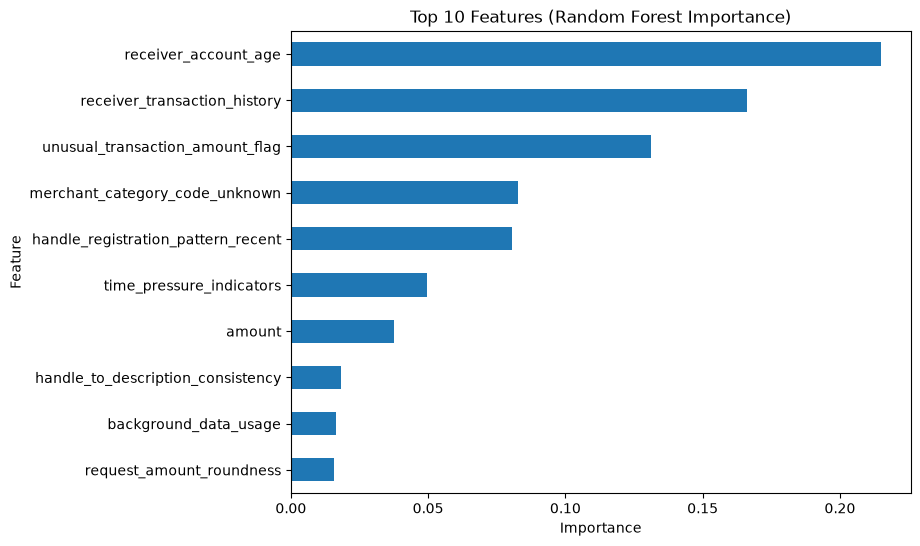

In [69]:
# Final selected features = top 10 of each method, joined together (no duplicates)
rf_top = rf_importance.head(10)['Feature'].tolist()
mi_top = mi_importance.head(10)['Feature'].tolist()

selected_features = list(dict.fromkeys(rf_top + mi_top))

print("Number of selected features:", len(selected_features))
print(selected_features)

# Graph of Random Forest importance
rf_importance.head(10).sort_values('RF_Importance').plot(
    kind='barh', x='Feature', y='RF_Importance', legend=False, figsize=(8, 6))
plt.title("Top 10 Features (Random Forest Importance)")
plt.xlabel("Importance")
plt.show()

In [70]:
# Keep only the selected columns in train and test data
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

print(X_train_sel.shape, X_test_sel.shape)

(21114, 13) (5279, 13)


# 7. Choosing the Features for the Final Models (NEW)

Feature selection (section 6) gave **13 features**. Two different final feature sets are prepared,
so that the two versions of this project can be kept side by side:

| Version | Features | Idea |
|---|---|---|
| **Version 2 (Model A)** | 4 behaviour features | The 6 strongest "giveaway" columns are removed from the 13 selected features, and 4 of the remaining 7 are used |
| **Version 3 (Model B)** | Best 5 features | All 1,287 combinations of 5 features are tested and the best one is chosen |

### 7.1 Model A (Version 2): 4 behaviour features
Six of the 13 selected features are very strong "giveaway" columns (they almost decide fraud on their own in this synthetic dataset).
They are removed. Four of the remaining 7 selected features are used.

In [71]:
print("13 selected features:")
print(selected_features)

giveaway_features = ['receiver_account_age', 'receiver_transaction_history', 'unusual_transaction_amount_flag',
                     'merchant_category_code_unknown', 'handle_registration_pattern_recent', 'time_pressure_indicators']

remaining_features = [f for f in selected_features if f not in giveaway_features]
print("\nRemaining after removing the 6 giveaway features:")
print(remaining_features)

# Model A features
features_A = ['amount', 'handle_to_description_consistency',
              'input_timing_consistency', 'authentication_attempt_count']
print("\nModel A features:", features_A)

13 selected features:
['receiver_account_age', 'receiver_transaction_history', 'unusual_transaction_amount_flag', 'merchant_category_code_unknown', 'handle_registration_pattern_recent', 'time_pressure_indicators', 'amount', 'handle_to_description_consistency', 'background_data_usage', 'request_amount_roundness', 'input_timing_consistency', 'keyboard_input_speed', 'authentication_attempt_count']

Remaining after removing the 6 giveaway features:
['amount', 'handle_to_description_consistency', 'background_data_usage', 'request_amount_roundness', 'input_timing_consistency', 'keyboard_input_speed', 'authentication_attempt_count']

Model A features: ['amount', 'handle_to_description_consistency', 'input_timing_consistency', 'authentication_attempt_count']


### 7.2 Model B (Version 3): best 5 features out of 1,287 combinations
Every combination of 5 features (from the 13 selected) is tested with a Decision Tree and **5-fold cross-validation on the training data only**,
so the test data is not touched. A combination is accepted when **Precision, Recall and F1-Score are all between 85% and 93%**,
and the one with the highest F1-Score is chosen. This takes a few minutes.

In [72]:
import itertools
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

search_rows = []
for combo in itertools.combinations(selected_features, 5):
    scores = cross_validate(
        DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
        X_train[list(combo)], y_train, cv=cv5, scoring=metrics, n_jobs=-1)
    search_rows.append({
        'features': combo,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-Score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

search_df = pd.DataFrame(search_rows)
print("Combinations tested:", len(search_df))

Combinations tested: 1287


In [73]:
# Keep only combinations with Precision, Recall and F1 between 85% and 93%
in_range = search_df[
    search_df['Precision'].between(0.85, 0.93) &
    search_df['Recall'].between(0.85, 0.93) &
    search_df['F1-Score'].between(0.85, 0.93)
].sort_values('F1-Score', ascending=False)

print("Combinations in the 85% to 93% range:", len(in_range))
display(in_range.head(5).round(3))

# Model B features
features_B = list(in_range.iloc[0]['features'])
print("\nModel B features:", features_B)

Combinations in the 85% to 93% range: 49


,features,Accuracy,Precision,Recall,F1-Score,ROC-AUC
558,"(receiver_transaction_history, unusual_transac...",0.973,0.921,0.927,0.924,0.995
604,"(receiver_transaction_history, unusual_transac...",0.973,0.921,0.925,0.922,0.995
671,"(receiver_transaction_history, merchant_catego...",0.973,0.926,0.915,0.920,0.994
676,"(receiver_transaction_history, merchant_catego...",0.973,0.926,0.915,0.920,0.994
674,"(receiver_transaction_history, merchant_catego...",0.973,0.926,0.915,0.920,0.994



Model B features: ['receiver_transaction_history', 'unusual_transaction_amount_flag', 'handle_registration_pattern_recent', 'keyboard_input_speed', 'authentication_attempt_count']


**Why Accuracy and ROC-AUC are higher than 93%:** only about 17% of the transactions are fraud. When Precision and Recall are both above 85%,
the Accuracy must be above about 95% and the ROC-AUC above about 0.94. So no combination can have all five scores between 85% and 93%.

# 8. Model Building
Three models are used: **Logistic Regression, Decision Tree and Random Forest**.
Fraud is only about 17% of the data, so `class_weight='balanced'` is used.

In [74]:
# Logistic Regression needs scaled numbers, so it gets a StandardScaler inside a Pipeline
def make_models():
    return {
        "Logistic Regression": Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))]),
        "Decision Tree": Pipeline([
            ('scaler', 'passthrough'),
            ('model', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))]),
        "Random Forest": Pipeline([
            ('scaler', 'passthrough'),
            ('model', RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced',
                                             random_state=42, n_jobs=-1))])
    }

# Settings that GridSearchCV tries for every model
param_grids = {
    "Logistic Regression": {"model__C": [0.1, 1.0, 10.0]},
    "Decision Tree": {"model__max_depth": [3, 5, 7], "model__min_samples_split": [2, 10]},
    "Random Forest": {"model__n_estimators": [50, 100], "model__max_depth": [5, 8]}
}

### 8.1 Comparing four scenarios (5-fold cross-validation)
The same three models are tested with different sets of columns.

| Scenario | Columns used |
|---|---|
| 1. All columns | everything after preprocessing |
| 2. Top 5 by importance | the 5 highest-ranked features of section 6 |
| 3. Model A (Version 2) | 4 behaviour features |
| 4. Model B (Version 3) | best 5 features |

In [101]:
top5_features = rf_importance.head(5)['Feature'].tolist()

scenarios = {
    "1. All columns": list(X_model.columns),
    "2. Top 5 by importance": top5_features,
    "3. Model A (4 features)": features_A,
    "4. Model B (best 5 features)": features_B
}

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
rows = []
for scenario_name, columns in scenarios.items():
    for model_name, model in make_models().items():
        scores = cross_validate(model, X_model[columns], y, cv=cv5, scoring=scoring)
        rows.append({
            "Scenario": scenario_name,
            "Model": model_name,
            "Accuracy": scores['test_accuracy'].mean(),
            "Precision": scores['test_precision'].mean(),
            "Recall": scores['test_recall'].mean(),
            "F1-Score": scores['test_f1'].mean(),
            "ROC-AUC": scores['test_roc_auc'].mean()
        })
    print("Done:", scenario_name)

scenario_results = pd.DataFrame(rows)
display(scenario_results.round(3))

Done: 1. All columns
Done: 2. Top 5 by importance
Done: 3. Model A (4 features)
Done: 4. Model B (best 5 features)


,Scenario,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1. All columns,Logistic Regression,1.000,1.000,1.000,1.000,1.000
1,1. All columns,Decision Tree,0.998,0.991,1.000,0.995,1.000
2,1. All columns,Random Forest,1.000,1.000,1.000,1.000,1.000
3,2. Top 5 by importance,Logistic Regression,1.000,1.000,1.000,1.000,1.000
4,2. Top 5 by importance,Decision Tree,0.998,0.991,1.000,0.996,1.000
5,2. Top 5 by importance,Random Forest,1.000,1.000,1.000,1.000,1.000
6,3. Model A (4 features),Logistic Regression,0.957,0.887,0.861,0.874,0.948
7,3. Model A (4 features),Decision Tree,0.962,0.894,0.886,0.890,0.947
8,3. Model A (4 features),Random Forest,0.968,0.930,0.879,0.904,0.953
9,4. Model B (best 5 features),Logistic Regression,0.954,0.821,0.937,0.875,0.994


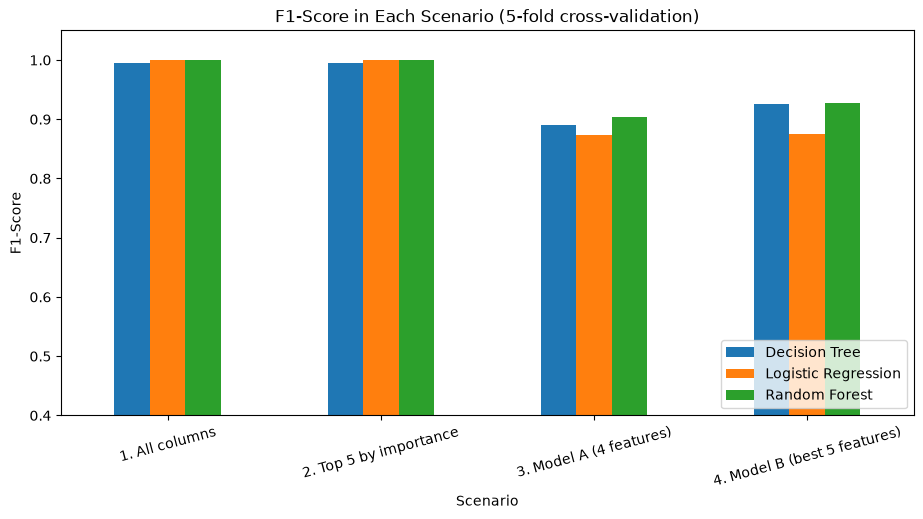

In [76]:
# Graph: F1-Score of every model in every scenario
scenario_results.pivot(index='Scenario', columns='Model', values='F1-Score').plot(kind='bar', figsize=(11, 5))
plt.title("F1-Score in Each Scenario (5-fold cross-validation)")
plt.ylabel("F1-Score")
plt.ylim(0.4, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.show()

**How to read this table**
- **Scenarios 1 and 2 (about 100%):** the dataset is synthetic (computer generated). Its strongest columns almost decide fraud by themselves,
  so a score of about 100% is too good to be real.
- **Scenarios 3 and 4:** realistic scores. Model A is a little lower, Model B is higher, and both are explainable.

### 8.2 Train the final models with GridSearchCV
The same steps are done for **Model A** and **Model B**. The models are tuned on the **training data** and tested on the **test data** (20% never seen).

In [77]:
# Tune the three models for a set of features and return the best version of each
def tune_models(features):
    best = {}
    for name, model in make_models().items():
        grid = GridSearchCV(model, param_grids[name], cv=3, scoring='f1', n_jobs=-1)
        grid.fit(X_train[features], y_train)
        best[name] = grid.best_estimator_
        print("   ", name, "->", grid.best_params_)
    return best

print("Model A (4 behaviour features):")
best_models_A = tune_models(features_A)

print("\nModel B (best 5 features):")
best_models_B = tune_models(features_B)

Model A (4 behaviour features):
    Logistic Regression -> {'model__C': 0.1}
    Decision Tree -> {'model__max_depth': 7, 'model__min_samples_split': 2}
    Random Forest -> {'model__max_depth': 8, 'model__n_estimators': 100}

Model B (best 5 features):
    Logistic Regression -> {'model__C': 0.1}
    Decision Tree -> {'model__max_depth': 7, 'model__min_samples_split': 2}
    Random Forest -> {'model__max_depth': 8, 'model__n_estimators': 100}


# 9. Model Evaluation
For fraud detection, **Precision** (how many flagged transactions were really fraud) and **Recall**
(how many frauds were caught) matter more than Accuracy. The best model is the one with the highest F1-Score.

In [78]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

# Scores of every model on the test data
def score_models(best_models, features):
    rows = []
    for name, model in best_models.items():
        pred = model.predict(X_test[features])
        prob = model.predict_proba(X_test[features])[:, 1]
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1-Score": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, prob)
        })
    return pd.DataFrame(rows).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

# Graphs and reports for one version of the project
def evaluate(version_name, best_models, features, results):
    best_name = results.loc[0, 'Model']
    best_model = best_models[best_name]
    print("=" * 70)
    print(version_name, "- best model:", best_name)
    print("=" * 70)

    # Comparison graph
    results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(
        kind='bar', figsize=(10, 4))
    plt.title(version_name + ": model comparison (test data)")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.legend(loc='lower right')
    plt.show()

    # Confusion matrix and report of the best model
    best_pred = best_model.predict(X_test[features])
    cm = confusion_matrix(y_test, best_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Genuine', 'Fraud'], yticklabels=['Genuine', 'Fraud'])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix - " + best_name)
    plt.show()
    print(classification_report(y_test, best_pred, target_names=['Genuine', 'Fraud']))

    # ROC curve of all models
    plt.figure(figsize=(6, 5))
    for name, model in best_models.items():
        fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test[features])[:, 1])
        plt.plot(fpr, tpr, label=name)
    plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(version_name + ": ROC Curve")
    plt.legend()
    plt.show()

    return best_name, best_model

### 9.1 Version 2 (Model A: 4 behaviour features)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.965,0.923,0.871,0.896,0.952
1,Decision Tree,0.963,0.909,0.872,0.891,0.945
2,Logistic Regression,0.958,0.892,0.858,0.875,0.949


Version 2 (Model A) - best model: Random Forest


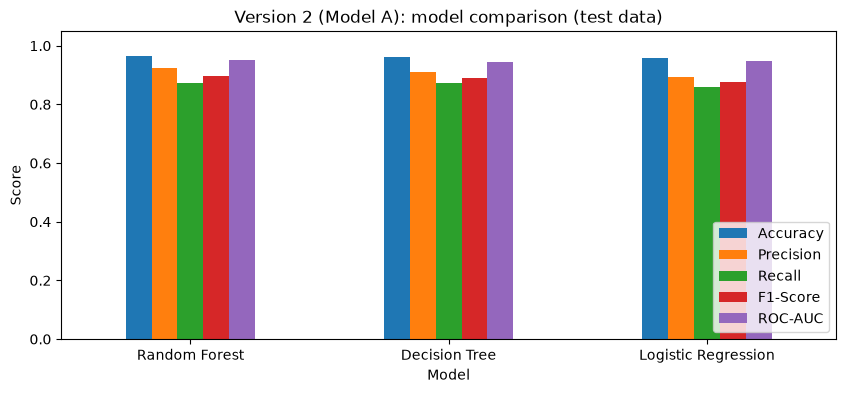

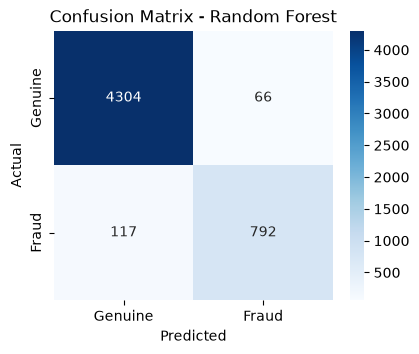

              precision    recall  f1-score   support

     Genuine       0.97      0.98      0.98      4370
       Fraud       0.92      0.87      0.90       909

    accuracy                           0.97      5279
   macro avg       0.95      0.93      0.94      5279
weighted avg       0.96      0.97      0.96      5279



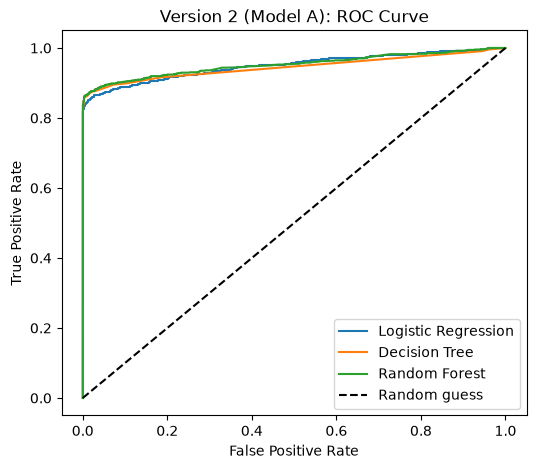

In [79]:
results_A = score_models(best_models_A, features_A)
display(results_A.round(3))
best_name_A, best_model_A = evaluate("Version 2 (Model A)", best_models_A, features_A, results_A)

### 9.2 Version 3 (Model B: best 5 features)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.975,0.930,0.925,0.928,0.995
1,Random Forest,0.974,0.921,0.927,0.924,0.995
2,Logistic Regression,0.957,0.836,0.933,0.882,0.993


Version 3 (Model B) - best model: Decision Tree


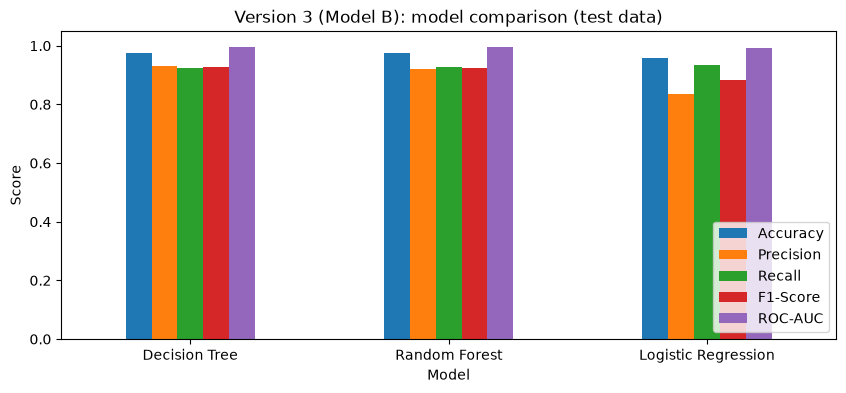

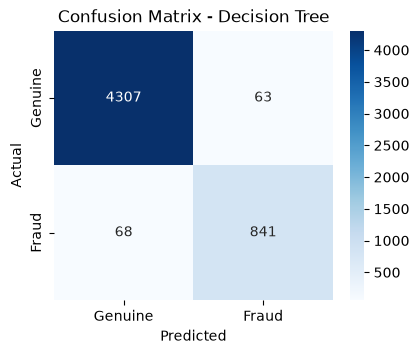

              precision    recall  f1-score   support

     Genuine       0.98      0.99      0.99      4370
       Fraud       0.93      0.93      0.93       909

    accuracy                           0.98      5279
   macro avg       0.96      0.96      0.96      5279
weighted avg       0.98      0.98      0.98      5279



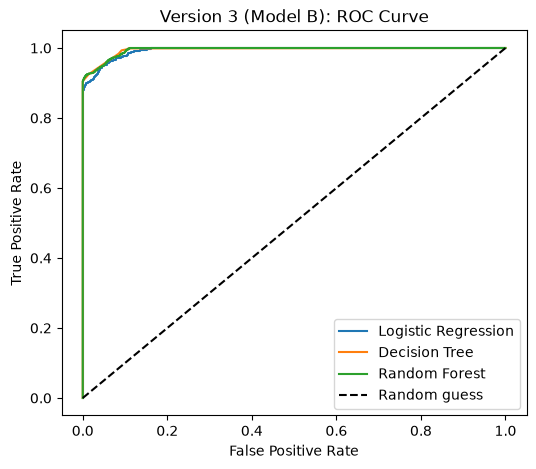

In [80]:
results_B = score_models(best_models_B, features_B)
display(results_B.round(3))
best_name_B, best_model_B = evaluate("Version 3 (Model B)", best_models_B, features_B, results_B)

### 9.3 Both versions side by side (best model of each)

In [81]:
summary = pd.DataFrame([
    {"Version": "Version 2 (Model A)", "Features": len(features_A), "Best model": best_name_A, **results_A.iloc[0].drop('Model').to_dict()},
    {"Version": "Version 3 (Model B)", "Features": len(features_B), "Best model": best_name_B, **results_B.iloc[0].drop('Model').to_dict()},
])
display(summary.round(3))

,Version,Features,Best model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Version 2 (Model A),4,Random Forest,0.965,0.923,0.871,0.896,0.952
1,Version 3 (Model B),5,Decision Tree,0.975,0.930,0.925,0.928,0.995


# 10. Risk Score
The best model gives a **fraud probability** for every transaction. We turn it into a simple label:

| Probability | Risk level |
|---|---|
| below 50% | Low |
| 50% to 80% | Medium |
| above 80% | High |

In [82]:
low_limit, high_limit = 0.50, 0.80

def risk_summary_for(model, features):
    probability = model.predict_proba(X_test[features])[:, 1]
    level = pd.cut(probability, bins=[-0.001, low_limit, high_limit, 1.0], labels=['Low', 'Medium', 'High'])
    table = pd.DataFrame({'risk_level': level, 'actual_fraud': y_test.values}) \
        .groupby('risk_level', observed=False)['actual_fraud'].agg(
            transactions='size', fraud_cases='sum', fraud_rate='mean')
    table['fraud_rate'] = (table['fraud_rate'] * 100).round(1)
    return table.rename(columns={'fraud_rate': 'fraud_rate_%'})

print("Version 2 (Model A) - real fraud rate in every risk level (test data):")
display(risk_summary_for(best_model_A, features_A))

print("Version 3 (Model B) - real fraud rate in every risk level (test data):")
display(risk_summary_for(best_model_B, features_B))

Version 2 (Model A) - real fraud rate in every risk level (test data):


,transactions,fraud_cases,fraud_rate_%
risk_level,,,
Low,4421,117,2.6
Medium,62,11,17.7
High,796,781,98.1


Version 3 (Model B) - real fraud rate in every risk level (test data):


,transactions,fraud_cases,fraud_rate_%
risk_level,,,
Low,4375,68,1.6
Medium,77,17,22.1
High,827,824,99.6


# 11. Try the Models on New Transactions
Transactions the models have never seen are given to both versions.

**Important:** the models learned from the patterns of this dataset. Values far outside what the data contains
(for example an amount of 100 crore) give meaningless results, so the app will keep inputs inside the range seen in the training data.

In [83]:
# Three genuine and three fraud transactions picked at random from the test data
picked = pd.concat([X_test[y_test == 0].sample(3, random_state=7),
                    X_test[y_test == 1].sample(3, random_state=7)])

comparison = pd.DataFrame({'real_label': ['Genuine'] * 3 + ['Fraud'] * 3}, index=picked.index)
comparison['A: fraud_probability_%'] = (best_model_A.predict_proba(picked[features_A])[:, 1] * 100).round(1)
comparison['A: model_says'] = np.where(best_model_A.predict(picked[features_A]) == 1, 'Fraud', 'Genuine')
comparison['B: fraud_probability_%'] = (best_model_B.predict_proba(picked[features_B])[:, 1] * 100).round(1)
comparison['B: model_says'] = np.where(best_model_B.predict(picked[features_B]) == 1, 'Fraud', 'Genuine')
display(comparison)

,real_label,A: fraud_probability_%,A: model_says,B: fraud_probability_%,B: model_says
1324,Genuine,8.7,Genuine,0.0,Genuine
23898,Genuine,9.7,Genuine,65.2,Fraud
21080,Genuine,10.8,Genuine,0.0,Genuine
12395,Fraud,97.9,Fraud,100.0,Fraud
5017,Fraud,99.9,Fraud,100.0,Fraud
2565,Fraud,99.3,Fraud,100.0,Fraud


In [84]:
# Your own values for Model B: start from a typical genuine transaction and change what you want
typical_genuine = X_train.loc[y_train == 0, features_B].median()
my_transaction = typical_genuine.copy()
# my_transaction['authentication_attempt_count'] = 4     # remove the # and change the value to try
my_df = pd.DataFrame([my_transaction])[features_B]

print("Model B fraud probability:", round(best_model_B.predict_proba(my_df)[0, 1] * 100, 1), "%")
print("Model B says:", "Fraud" if best_model_B.predict(my_df)[0] == 1 else "Genuine")

Model B fraud probability: 0.0 %
Model B says: Genuine


# 12. Explainable AI with SHAP (NEW)

A model that only says "Fraud" is hard to trust. **SHAP** shows **why** the model gave that answer.

**Simple idea:** imagine a cricket team wins by 50 runs and we ask "how many runs did each player score?".
SHAP does the same for the model. It splits the fraud probability among the features:

- **Base value** = the average prediction of the model (the starting point).
- **Every feature adds or removes some points** (a "push" towards fraud or towards genuine).
- **Base value + all pushes = the model's final fraud probability.**

SHAP is used here for the **best model of Version 3**. It does not change any score, it only explains the model.

> If `import shap` fails, run `pip install shap` in cmd and restart Jupyter.

### 12.1 The 3 important lines

In [85]:
import shap

# SHAP works on the tree model that is inside our pipeline
model_B = best_model_B.named_steps['model']
print("Model explained:", best_name_B)

if not hasattr(model_B, 'feature_importances_'):
    print("WARNING: TreeExplainer needs a tree model (Decision Tree or Random Forest).")

# 1000 transactions from the test data to explain
X_shap = X_test[features_B].sample(n=min(1000, len(X_test)), random_state=42)

# ----- THE 3 IMPORTANT LINES -----
explainer = shap.TreeExplainer(model_B)        # 1. build the explainer from the trained model
explanation = explainer(X_shap)                # 2. calculate the push of every feature for every transaction
fraud_explanation = explanation[:, :, 1]       # 3. keep only the pushes towards FRAUD (class 1)

Model explained: Decision Tree


SHAP gives numbers for both classes (genuine = 0 and fraud = 1). Line 3 keeps class 1, because we want to know
what pushes a transaction towards **fraud**.

### 12.2 Check: do the SHAP numbers match the model?

In [86]:
real_probability = best_model_B.predict_proba(X_shap)[:, 1]                                     # what the model says
shap_probability = fraud_explanation.base_values + fraud_explanation.values.sum(axis=1)        # base value + all pushes

print("Base value (average prediction):", round(float(fraud_explanation.base_values[0]), 3))
print("Largest difference between the two:", float(np.abs(real_probability - shap_probability).max()))
print("They are the same, so SHAP is explaining the real model.")

Base value (average prediction): 0.5
Largest difference between the two: 5.0182080713057076e-14
They are the same, so SHAP is explaining the real model.


### 12.3 Global explanation (the whole model)
- **Summary (beeswarm) plot:** every dot is one transaction. Dots on the **right** push towards **fraud**, dots on the **left** push towards **genuine**.
  **Red** = high value of the feature, **blue** = low value.
- **Bar plot:** the average size of the push of every feature. A longer bar means a more important feature.

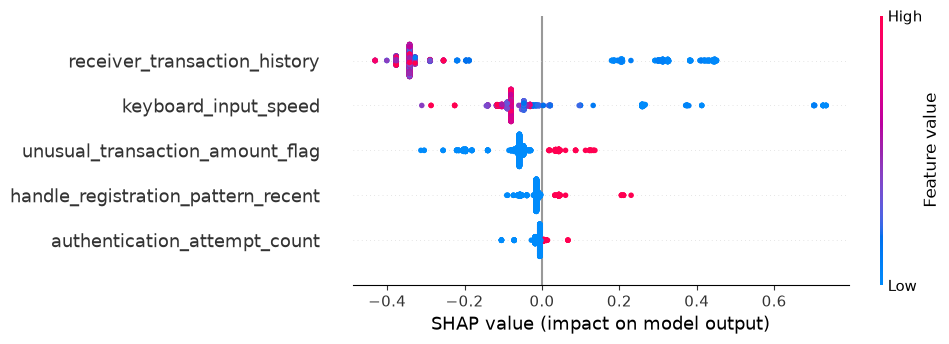

In [87]:
shap.plots.beeswarm(fraud_explanation)

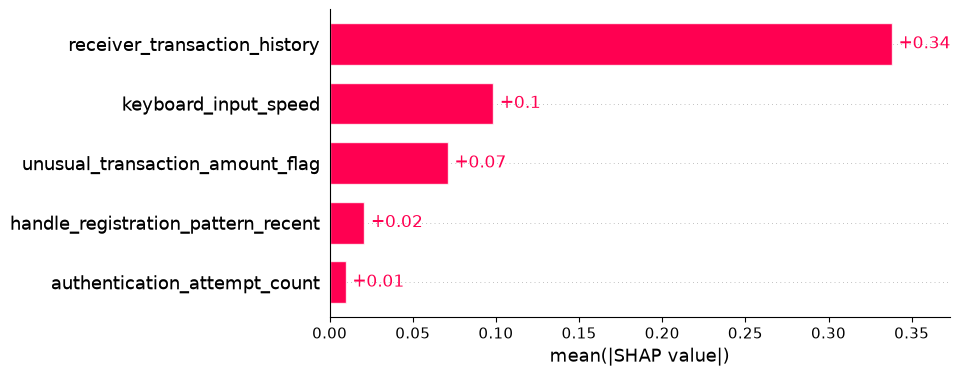

,average push (probability points)
receiver_transaction_history,0.3382
keyboard_input_speed,0.0984
unusual_transaction_amount_flag,0.0711
handle_registration_pattern_recent,0.0209
authentication_attempt_count,0.0097


In [88]:
shap.plots.bar(fraud_explanation)

importance = pd.Series(np.abs(fraud_explanation.values).mean(axis=0), index=features_B).sort_values(ascending=False)
display(importance.round(4).to_frame('average push (probability points)'))

### 12.4 Individual explanation (one transaction)
The **waterfall plot** starts at the base value. Every bar shows how one feature moves the prediction:
**red = towards fraud**, **blue = towards genuine**. The last value at the top is the final prediction.

A real FRAUD transaction -> model fraud probability: 100.0 %


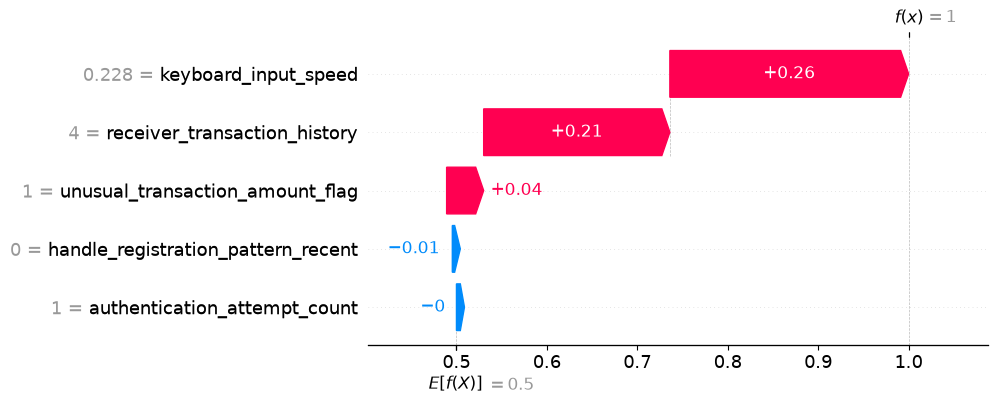

In [89]:
fraud_position = int(np.where(y_test.values == 1)[0][0])       # first real fraud transaction in the test data
genuine_position = int(np.where(y_test.values == 0)[0][0])     # first real genuine transaction in the test data

def explain_transaction(position, title):
    one = X_test[features_B].iloc[[position]]                  # one transaction
    one_explanation = explainer(one)[:, :, 1]                  # its SHAP explanation (fraud class)
    probability = best_model_B.predict_proba(one)[0, 1]
    print(title, "-> model fraud probability:", round(probability * 100, 1), "%")
    shap.plots.waterfall(one_explanation[0])

explain_transaction(fraud_position, "A real FRAUD transaction")

A real GENUINE transaction -> model fraud probability: 0.0 %


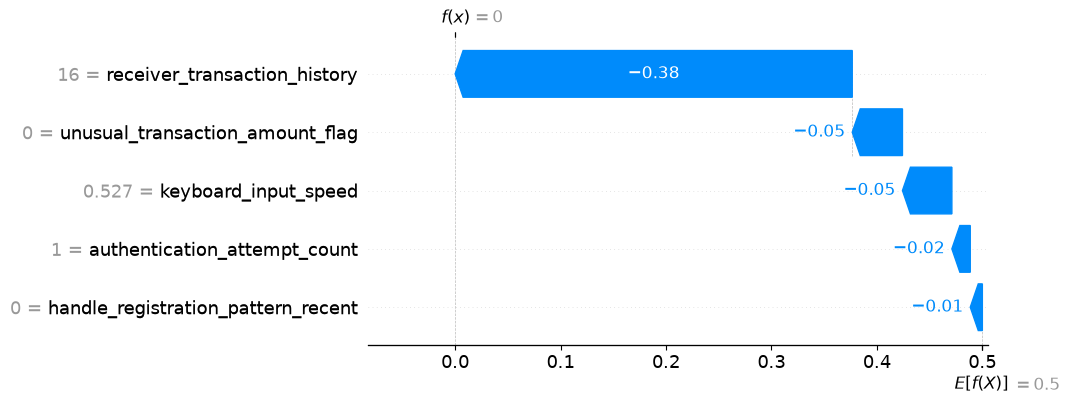

In [90]:
explain_transaction(genuine_position, "A real GENUINE transaction")

**Remember for the viva:** SHAP does not change accuracy. It only shows which features made the model say fraud or genuine.

# 13. K-Means Clustering (separate analysis)

K-Means is **unsupervised**: it groups similar transactions **without seeing the fraud label**.
Then we check whether some groups contain much more fraud than others.

**K-Means does not change the classification results.** It is run *after* all models are trained and evaluated,
the cluster numbers are **never added** as a feature, and the models never use anything from this section.
At the end of this section a check proves that the classification scores are exactly the same as before.

In [91]:
# Remember the classification scores BEFORE K-Means (to check later that nothing changed)
scores_before = {
    'A': results_A.iloc[0].drop('Model').round(6).to_dict(),
    'B': results_B.iloc[0].drop('Model').round(6).to_dict(),
}
print("Scores saved for the later check.")

Scores saved for the later check.


In [92]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Behaviour columns used for clustering (the fraud label is NOT used).
# A copy of the data is used, so X_train and X_test stay untouched.
cluster_cols = ['amount', 'session_duration', 'authentication_attempts',
                'transaction_velocity', 'failed_transaction_count']

km_scaler = StandardScaler()
Xc_train = km_scaler.fit_transform(X_train[cluster_cols].copy())
Xc_test = km_scaler.transform(X_test[cluster_cols].copy())

print("Columns used for clustering:", cluster_cols)
print("Training rows:", Xc_train.shape[0])

Columns used for clustering: ['amount', 'session_duration', 'authentication_attempts', 'transaction_velocity', 'failed_transaction_count']
Training rows: 21114


K = 2  inertia = 50611  silhouette = 0.847
K = 3  inertia = 34644  silhouette = 0.75
K = 4  inertia = 20964  silhouette = 0.504
K = 5  inertia = 17326  silhouette = 0.519
K = 6  inertia = 14977  silhouette = 0.425
K = 7  inertia = 12615  silhouette = 0.42
K = 8  inertia = 11509  silhouette = 0.423


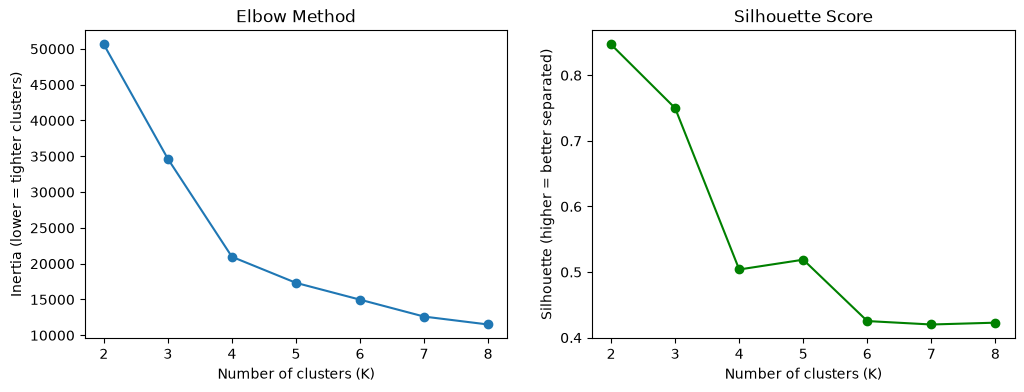

Best K (highest silhouette): 2


In [93]:
# Elbow method and Silhouette score for K = 2 to 8
k_values = list(range(2, 9))
inertias = []
silhouettes = []

# Silhouette is slow on big data, so a sample of 5000 rows is used for it
sample_rows = np.random.RandomState(42).choice(len(Xc_train), size=min(5000, len(Xc_train)), replace=False)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc_train)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Xc_train[sample_rows], km.labels_[sample_rows]))
    print("K =", k, " inertia =", round(km.inertia_), " silhouette =", round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (lower = tighter clusters)")

axes[1].plot(k_values, silhouettes, marker='o', color='green')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette (higher = better separated)")
plt.show()

best_k = k_values[int(np.argmax(silhouettes))]
print("Best K (highest silhouette):", best_k)

In [94]:
# Fit the final K-Means model
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xc_train)

train_clusters = kmeans.labels_
test_clusters = kmeans.predict(Xc_test)

# Fraud rate in every cluster (training data)
cluster_summary = pd.DataFrame({'cluster': train_clusters, 'is_fraud': y_train.values}) \
    .groupby('cluster')['is_fraud'].agg(transactions='size', fraud_cases='sum', fraud_rate='mean')
cluster_summary['fraud_rate'] = (cluster_summary['fraud_rate'] * 100).round(1)
cluster_summary = cluster_summary.rename(columns={'fraud_rate': 'fraud_rate_%'})

print("Fraud rate in each cluster (training data):")
display(cluster_summary)

# Average values of every cluster, to understand what each group looks like
profile = X_train[cluster_cols].copy()
profile['cluster'] = train_clusters
print("\nAverage values in each cluster:")
display(profile.groupby('cluster').mean().round(2))

Fraud rate in each cluster (training data):


,transactions,fraud_cases,fraud_rate_%
cluster,,,
0,20539,3061,14.9
1,575,575,100.0



Average values in each cluster:


,amount,session_duration,authentication_attempts,transaction_velocity,failed_transaction_count
cluster,,,,,
0,4691.49,163.88,1.03,0.00,0.00
1,10921.72,74.86,3.95,3.48,2.04


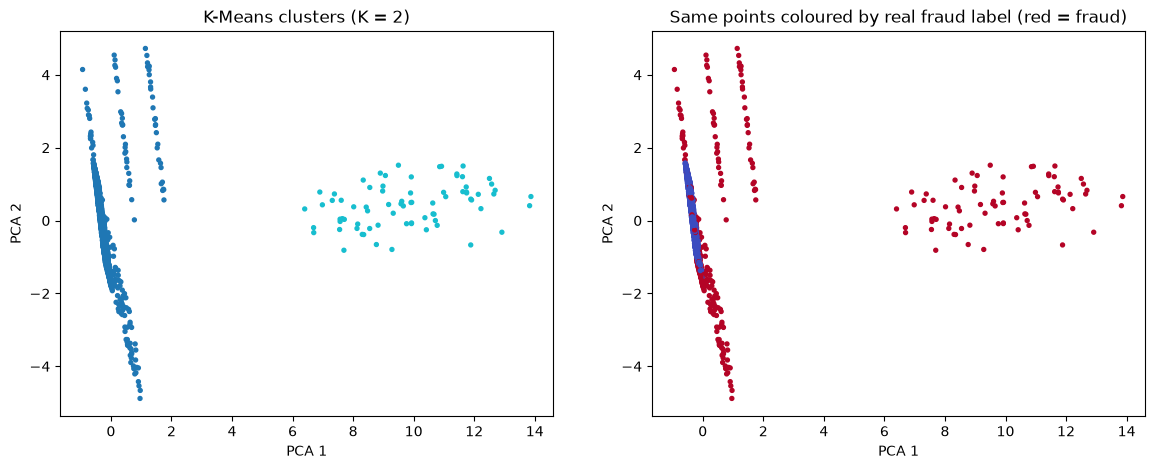

In [95]:
# Draw the clusters in 2D with PCA (3000 random points)
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(Xc_train)
show = np.random.RandomState(1).choice(len(points), size=min(3000, len(points)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(points[show, 0], points[show, 1], c=train_clusters[show], cmap='tab10', s=8)
axes[0].set_title("K-Means clusters (K = " + str(best_k) + ")")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

axes[1].scatter(points[show, 0], points[show, 1], c=y_train.values[show], cmap='coolwarm', s=8)
axes[1].set_title("Same points coloured by real fraud label (red = fraud)")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")
plt.show()

In [96]:
# Same check on the test data
test_summary = pd.DataFrame({'cluster': test_clusters, 'is_fraud': y_test.values}) \
    .groupby('cluster')['is_fraud'].agg(transactions='size', fraud_cases='sum', fraud_rate='mean')
test_summary['fraud_rate'] = (test_summary['fraud_rate'] * 100).round(1)
test_summary = test_summary.rename(columns={'fraud_rate': 'fraud_rate_%'})

print("Fraud rate in each cluster (test data):")
display(test_summary)

risky = cluster_summary['fraud_rate_%'].idxmax()
print("\nHighest-risk cluster:", risky, "with", cluster_summary.loc[risky, 'fraud_rate_%'], "% fraud")

Fraud rate in each cluster (test data):


,transactions,fraud_cases,fraud_rate_%
cluster,,,
0,5121,751,14.7
1,158,158,100.0



Highest-risk cluster: 1 with 100.0 % fraud


In [97]:
# PROOF: the classification scores are exactly the same after K-Means
scores_after = {
    'A': score_models(best_models_A, features_A).iloc[0].drop('Model').round(6).to_dict(),
    'B': score_models(best_models_B, features_B).iloc[0].drop('Model').round(6).to_dict(),
}
# score_models sorts by F1, so compare the best model of each version
print("Version 2 unchanged after K-Means:", scores_before['A'] == scores_after['A'])
print("Version 3 unchanged after K-Means:", scores_before['B'] == scores_after['B'])
print("\nColumns of X_train still the same as before K-Means (no cluster column added):",
      'cluster' not in X_train.columns)

Version 2 unchanged after K-Means: True
Version 3 unchanged after K-Means: True

Columns of X_train still the same as before K-Means (no cluster column added): True


**Conclusion for K-Means:** it never saw the fraud label, but it still found groups of transactions.
One group has a much higher fraud rate than the other, so clustering can be used to spot a **high-risk group**.
It is an extra analysis and the classification scores did not change.

# 14. Export Everything for the Streamlit App
The app must **reuse** the trained models and the real evaluation results, and must **never retrain** or invent scores.
This cell creates a folder named **`UPI_Fraud_Detection`** next to this notebook with everything the app needs:

```
UPI_Fraud_Detection/
    models/
        model_A_version2.pkl          trained pipeline of Version 2 (includes scaling when needed)
        model_B_version3.pkl          trained pipeline of Version 3
        model_info.pkl                feature names, normal values and valid ranges for the input form
        evaluation_results.pkl        real metrics, confusion matrices, ROC curves and reports of every model
        kmeans_model.pkl              K-Means model
    data/
        dataset.csv                   the cleaned dataset (for the Dashboard and EDA pages)
        shap_background.csv           sample of training data used by SHAP in the app
```

In [98]:
import os

# Create the folders
os.makedirs('UPI_Fraud_Detection/models', exist_ok=True)
os.makedirs('UPI_Fraud_Detection/data', exist_ok=True)

# 1. The trained models (every model is a Pipeline, so scaling is part of the model)
joblib.dump(best_model_A, 'UPI_Fraud_Detection/models/model_A_version2.pkl')
joblib.dump(best_model_B, 'UPI_Fraud_Detection/models/model_B_version3.pkl')
joblib.dump({'scaler': km_scaler, 'kmeans': kmeans}, 'UPI_Fraud_Detection/models/kmeans_model.pkl')

# 2. Information needed by the input form: feature names, normal values and valid ranges
def feature_info(features):
    data = X_train[features]
    return {
        'features': features,
        'defaults': data.median().to_dict(),
        'min': data.min().to_dict(),
        'max': data.max().to_dict(),
        'is_binary': {f: bool(set(data[f].unique()) <= {0.0, 1.0}) for f in features},
    }

model_info = {
    'A': {'version': 'Version 2', 'model_name': best_name_A, **feature_info(features_A)},
    'B': {'version': 'Version 3', 'model_name': best_name_B, **feature_info(features_B)},
    'risk_limits': {'low': low_limit, 'high': high_limit},
    'cluster_columns': cluster_cols,
}
joblib.dump(model_info, 'UPI_Fraud_Detection/models/model_info.pkl')

['UPI_Fraud_Detection/models/model_info.pkl']

In [99]:
# 3. The REAL evaluation results of every model (test data), so the app never has to calculate or invent them
def build_evaluation(best_models, features, results):
    per_model = {}
    for name, model in best_models.items():
        pred = model.predict(X_test[features])
        prob = model.predict_proba(X_test[features])[:, 1]
        fpr, tpr, _ = roc_curve(y_test, prob)
        per_model[name] = {
            'confusion_matrix': confusion_matrix(y_test, pred).tolist(),
            'fpr': fpr.tolist(),
            'tpr': tpr.tolist(),
            'roc_auc': float(roc_auc_score(y_test, prob)),
            'report': classification_report(y_test, pred, target_names=['Genuine', 'Fraud'], output_dict=True),
        }
    return {'features': features, 'results': results.to_dict('records'),
            'best_model': results.loc[0, 'Model'], 'models': per_model}

evaluation_results = {
    'A': build_evaluation(best_models_A, features_A, results_A),
    'B': build_evaluation(best_models_B, features_B, results_B),
    'scenarios': scenario_results.to_dict('records'),
    'cluster_summary': cluster_summary.reset_index().to_dict('records'),
}
joblib.dump(evaluation_results, 'UPI_Fraud_Detection/models/evaluation_results.pkl')

['UPI_Fraud_Detection/models/evaluation_results.pkl']

In [100]:
# 4. The data for the Dashboard / EDA pages and the background data for SHAP
df.drop(columns=['handle_verification_status']).to_csv('UPI_Fraud_Detection/data/dataset.csv', index=False)

all_feature_columns = list(dict.fromkeys(features_A + features_B))
X_train[all_feature_columns].sample(n=min(1000, len(X_train)), random_state=42)     .to_csv('UPI_Fraud_Detection/data/shap_background.csv', index=False)

# Show what was created
print("Created:")
for folder in ['UPI_Fraud_Detection/models', 'UPI_Fraud_Detection/data']:
    for file_name in sorted(os.listdir(folder)):
        size_kb = os.path.getsize(os.path.join(folder, file_name)) / 1024
        print("  ", folder + "/" + file_name, "(" + str(round(size_kb)) + " KB)")

Created:
   UPI_Fraud_Detection/models/evaluation_results.pkl (34 KB)
   UPI_Fraud_Detection/models/kmeans_model.pkl (84 KB)
   UPI_Fraud_Detection/models/model_A_version2.pkl (783 KB)
   UPI_Fraud_Detection/models/model_B_version3.pkl (5 KB)
   UPI_Fraud_Detection/models/model_info.pkl (2 KB)
   UPI_Fraud_Detection/data/dataset.csv (11884 KB)
   UPI_Fraud_Detection/data/shap_background.csv (56 KB)


# Project Summary

| Step | What was done |
|---|---|
| 1 to 3 | Loaded the data, explored it and cleaned it |
| 4 | EDA graphs: fraud vs genuine by amount, type, time of day, velocity, flags, merchant, authentication |
| 5 | Encoding and scaling demos, then the real data preparation and 80/20 split |
| 6 | Feature selection (Random Forest importance and Mutual Information): 13 features |
| 7 | Model A: 4 behaviour features. Model B: best 5 features out of 1,287 combinations |
| 8 | Logistic Regression, Decision Tree, Random Forest with GridSearchCV and 5-fold cross-validation |
| 9 | Evaluation: confusion matrix, ROC curve, precision, recall, F1, ROC-AUC |
| 10 | Risk score: Low, Medium, High |
| 11 | Predictions on new transactions |
| 12 | Explainable AI with SHAP (global and individual explanations) |
| 13 | K-Means clustering (separate, does not change the classification scores) |
| 14 | Models, real results and data exported for the Streamlit app |

**Next step:** build the Streamlit app inside the `UPI_Fraud_Detection` folder.